# Assignment 3: Dissipative Particle Dynamics

**6EMA02 Particle-based Simulations, 2026-2027 edition**
Mesoscale simulation · soft repulsive beads · demixing and interfaces

## How this assignment is assessed: read this first

This notebook is both the assignment text and your report. Task cells
(like this one) are the assignment text and are marked read-only. Jupyter
enforces that; some editors (VS Code among them) do not, so simply leave
them untouched either way: hand-ins are checked against the released
notebook, and modified task cells are flagged. You write your answers in
the cells below each task and hand in this same notebook, **executed**,
together with an HTML export, your code, and the data files the notebook
loads (layout at the end of this notebook).

Your report is **not graded on its content**. Its result is determined in
the individual oral examination at the end of the quartile: the exam is a
conversation about *your* code and *your* results, with this notebook on
screen. Write it as your defence dossier: concise, bullet answers are
fine, every claim something you can stand behind. A report you never hand
in scores 0 for its weight in the final grade; a handed-in report's
result *is* your oral grade.

**AI and sources.** You may use AI assistants (ChatGPT, Claude, Copilot,
…) freely in this course, for code, analysis, and text. Declare the use
briefly in the *Sources* section below, along with any other external
sources: anything in your submission (code, text, data, results) that
your group did not produce itself. Declared sources are never penalised:
nobody grades the text of your report or the style of your code. The oral
examination assesses what *you* understand about the simulation you hand
in. Anything in your submission is fair game, and "we didn't write that
part" is not an available answer. Presenting undeclared external work as
your own is academic misconduct and is treated as such.

## Group

- **Group ID:** …
- **Members:** name (student ID), name (student ID)

## The physics: why a mesoscale method exists

Your A2 code integrates the motion of individual molecular sites with a
time step of about a femtosecond. Now consider what you would need to
simulate a droplet of oil in water demixing, or a polymer solution
flowing through a channel: micrometres of space and microseconds of time.
That is roughly $10^{12}$ sites and $10^{9}$ steps. Molecular dynamics
cannot get there, and continuum fluid mechanics cannot resolve the
individual polymer chains that matter. **Dissipative particle dynamics
(DPD) lives in that gap.**

The trick is **coarse-graining**. One DPD bead is not an atom: it stands
for a lump of fluid, a cluster of molecules moving together. Because a
bead is a soft blob rather than a hard molecule, two beads may overlap,
and the repulsion between them is **soft**:

$$\mathbf{F}^C_{ij} = a_{ij}\left(1 - \frac{r_{ij}}{r_c}\right)
\hat{\mathbf{r}}_{ij} \quad \text{for } r_{ij} < r_c,$$

finite even at $r_{ij} = 0$. No $r^{-12}$ wall means no violently fast
collisions, which is what buys the very large time steps that make the
method useful.

Coarse-graining throws away degrees of freedom, and they must come back
as noise and friction. DPD adds two more pair forces:

$$\mathbf{F}^D_{ij} = -\gamma\, \omega^D(r_{ij})
(\hat{\mathbf{r}}_{ij} \cdot \mathbf{v}_{ij})\, \hat{\mathbf{r}}_{ij},
\qquad
\mathbf{F}^R_{ij} = \sigma\, \omega^R(r_{ij})\, \frac{\zeta_{ij}}
{\sqrt{\Delta t}}\, \hat{\mathbf{r}}_{ij}.$$

The dissipative force damps the *relative* velocity of a pair, the random
force kicks it. Neither is arbitrary: the **fluctuation-dissipation
theorem** ties their amplitudes and their weight functions together
(Eq. (5) of the paper, with $\omega^D = [\omega^R]^2$ and
$\sigma^2 = 2\gamma k_BT$). Get that relation wrong and your system
simply equilibrates to the wrong temperature, which is exactly what task
B3 checks.

The decisive property is that **all three forces act pairwise along the
line between beads**, so they conserve momentum. That is the difference
between DPD and Brownian or Langevin dynamics, where the friction is with
an implicit background that absorbs momentum. Conserved momentum means
the correct long-wavelength behaviour emerges by itself: DPD reproduces
hydrodynamics, so a DPD fluid flows, carries shear, and mediates
hydrodynamic interactions between suspended objects. That is what makes
it a *mesoscale* method rather than a fast approximation.

What does a bead stand for, quantitatively? Groot and Warren fix that by
matching the compressibility of water at $\rho = 3$, giving
$a_{ii} \approx 25\, k_BT/r_c$ for beads of the same type. Different
types repel more strongly, $a_{ij} > a_{ii}$, and the excess drives
demixing. The link to polymer physics is the Flory-Huggins parameter
$\chi$, which you will measure in task C3 and which turns out to depend
linearly on $\Delta a = a_{AB} - a_{AA}$. Add springs between beads and
you have polymer chains, whose demixing at much smaller $\Delta a$ (the
$\chi N$ of Eq. (27)) is the subject of Part D.

## What you will do, and the reference paper

You will convert **your own MD code from Assignment 2** into a DPD code,
verify it, and then use it to reproduce published results. There is no
new starting code for A3, and so no `\todo` list to guide you: everything
you have to build is stated in this notebook, in the section *From your
A2 code to a DPD code* below and in the task texts. Read both before you
change a line.

The reference is Groot and Warren, *J. Chem. Phys.* **107**, 4423
(1997), handed out under Files ▸ Papers. Equation and figure numbers in
this notebook refer to that paper. Reproducing a published result is the
strongest form of validation available to you here: the numbers exist
independently of your code, so agreement is evidence and disagreement is
information.

**Units: not the units of A2.** In A2 the energy unit was $k_B \times
1$ K, lengths were in Å and masses in amu, so $k_BT = 293$, the masses
were about 15, the cut-off was 14 and the time step 0.001 (about 1 fs).
DPD uses its own reduced units: the cut-off distance $r_c$ of the DPD
interactions is the unit of length, the bead mass $m$ the unit of mass,
and the thermal energy $k_BT$ the unit of energy. The time unit follows
as $r_c\sqrt{m/k_BT}$. So $r_c = m = k_BT = 1$, and **every number in
your A2 `setparameters.c` changes**; the table in the next section lists
them. Report everything in these units unless you say otherwise.

**The integrator stays.** Groot and Warren's Eq. (9) is a velocity-Verlet
step in which the velocity-dependent forces of the new time step are
evaluated with a predicted velocity $\tilde{\mathbf{v}} = \mathbf{v}(t) +
\lambda \Delta t\, \mathbf{f}(t)/m$. Your A2 loop already does this with
$\lambda = 1/2$: it calls `calculate_forces` after the first half kick and
the position update, so the velocities the force routine sees are exactly
$\mathbf{v}(t) + \tfrac12 \Delta t\, \mathbf{f}(t)/m$. Keep the loop as it
is. Use $\Delta t = 0.04$ for all thermostatted runs, as the paper does.

Expect the conversion to be where the bugs are. Take small steps, run a
short simulation after each change, and look at it in OVITO before you
measure anything.

**Your working environment** is the one you set up for A1 and A2: the
`pbs-env` environment from `requirements.txt`, `nb2html.py` for the HTML
you hand in, and `check_my_submission.py` before you submit. See the
Canvas page *Working on the assignments*.

## From your A2 code to a DPD code

This is the inventory: what you can keep, what you must change, and what
you must write from nothing. Names refer to the A2 starting code; if you
renamed things in A2, map them onto your own.

**Keep as it is.** The velocity-Verlet loop in `main.c` and the two
routines in `dynamics.c` it calls (`update_velocities_half_dt`,
`update_positions`); `boundary_conditions`; the cell list and neighbour
list in `nbrlist.c`; `v3_min_image` and the other vector helpers; the
restart files; the bond list built in
`initialise_bond_connectivity` and `initialise_structure`; and the
finite-difference force test. The test still works for the conservative
force and the springs, which derive from a potential, provided you switch
the dissipative and random forces off while it runs; it cannot test those
two, which derive from no potential.

**Change.**

| A2 | A3 |
|---|---|
| $k_BT = 293$, masses 15.035 and 14.027 | $k_BT = 1$, both masses 1 |
| `r_cut = 14`, `r_shell = 1` | `r_cut = 1`, `r_shell` about 0.3 to 0.4 |
| `dt = 1e-3` | `dt = 0.04` (task B1 uses smaller values) |
| cubic box from the mass density | box in units of $r_c$, `num_part` $= \rho L_x L_y L_z$ with $\rho = 3$ (see the run plan) |
| Lennard-Jones $\epsilon_{ij}$, $\sigma_{ij}$ per type pair | DPD repulsion $a_{ij}$ per type pair; two types, A and B |
| bond $\tfrac12 k_b (r - r_0)^2$, $r_0 = 1.54$ | the same routine with $r_0 = 0$ and $k_b = C = 2$: that *is* Eq. (25) |
| angle and torsion terms | **removed**: delete their calls from `calculate_forces`. `initialise_structure` derives angles and dihedrals from the bonds by itself, so leaving the calls in applies pentane angle and torsion forces to your chains |
| `factor_12_nb = factor_13_nb = factor_14_nb = 0` | **all three equal to 1**: in DPD bonded beads also repel each other (task A2) |
| CH$_3$ and CH$_2$ in fixed pentane order | type A or B per chain, a chosen fraction of each (task A2) |
| 5 sites per molecule, 4 bonds | chains of $N$ beads, $N - 1$ bonds; $N = 1$ means no bonds at all |
| pentanes on a lattice | random-walk chains, optionally A and B in separate halves of the box (task A2, Part C) |
| Berendsen thermostat, `is_NVT = 1` | **removed**: the dissipative and random forces are the thermostat, and rescaling the velocities on top of them destroys the fluctuation-dissipation balance they rely on |
| output and sampling intervals, in steps | check each one: a step is now $0.04$ time units, not 1 fs |
| `record_trajectories_pdb` labels every site C | OVITO then sees one particle type. If your A beads come first, colour by index: *Expression selection* with `ParticleIndex <` (number of A beads), then *Assign color*. Otherwise write the type into the file, for instance as the element name: one line in the writer |

**Write new.**

- The three DPD pair forces in `calculate_forces_nb` (task A1). They need
  the velocities and the time step, which the Lennard-Jones loop never
  used, and a source of random numbers.
- Two switches in `setparameters.c`, one for the conservative force and
  one for the dissipative and random forces together. Part B runs with
  each of them off in turn.
- On-the-fly analysis, most of it new: $g(r)$ per type pair (A3); the
  velocity distribution (B3), which you may already have from A2; the
  composition profile along $x$ (Part C); the diagonal components of the
  pressure tensor (C4); the end-to-end distance of the chains (D1).

## The runs, at a glance

Every run is a separate compilation with its own `setparameters.c`
values, as in A2. Density $\rho = 3$ throughout and
$a_{AA} = a_{BB} = 25$; $\Delta a = a_{AB} - 25$. The step counts are a
suggestion that is known to be enough. For orientation, a reference DPD
code of the same structure as yours does 60 000 steps of 6000 beads in
about five minutes on one core.

| runs | box | beads | $N$ | $a_{AB}$ | switches, $\Delta t$ | steps | tasks |
|---|---|---|---|---|---|---|---|
| energy | $10^3$ | 3000 | 1 | 25 | dissipative and random **off**; $\Delta t$ = 0.04, 0.02, 0.01, 0.005; start from the end of the monomer-fluid run | to $t = 200$ | B1 |
| ideal gas | $10^3$ | 3000 | 1 | 25 | conservative **off** | 20 000 | B2, B3 |
| monomer fluid | $10^3$ | 3000 | 1 | 25 | all on | 20 000 | B3, C1 |
| Fig. 6 | $20\times10\times10$ | 6000 | 1 | 37 | all on, separated start | 60 000 | C2 |
| χ series | $20\times10\times10$ | 6000 | 1 | 35, 39, 43, 47 | all on, separated start | 60 000 each | C3, C4 |
| control | $20\times10\times10$ | 6000 | 1 | 25 | all on, separated start | 60 000 | C4 |
| chains | $10^3$ | 3000 | 5 | 25 | all on | 20 000 | D1 |
| chain demixing | $20\times10\times10$ | 6000 | 3, 5, 10 | 28 | all on, separated start | 60 000 each | D2, D3 |
| chain χ series | $20\times10\times10$ | 6000 | 3; 5; 10 | 30, 32; 27, 28.5, 30; 26, 26.5, 27 | all on, separated start | 60 000 each | D3 |

Long runs are done in the terminal, never from the notebook; let the
notebook load their output from `data/`.

## Code map: Part A working version

**Status:** A1–A3 implemented and checked in the assistant's Linux environment,
then compiled and checked on the user's M1 Mac. The plots below now use the
Mac-generated data. OVITO loading/playback was confirmed by the user.
Parts B–D remain unfinished; group details and review for the oral are still needed.

| Task | File / function(s) | Data files |
|---|---|---|
| A1 DPD forces | [`calculate_forces_nb`, `dpd_noise`, `calculate_forces_bond`](code/forces.c); [integration loop](code/main.c) | [checks](data/a_mac_checks_transcript.log), [smoke thermodynamics](data/a_smoke_thermo.csv) |
| A2 bead-spring chains, initialisation | [`initialise_types`, `initialise_bond_connectivity`, `initialise_positions`](code/initialise.c); [settings](code/setparameters.c) | [chain checks](data/a_mac_checks_transcript.log) |
| A3 g(r) | [`rdf_sample`, `analysis_update`, `write_hist`](code/analysis.c) | [uniform RDF](data/a_uniform_rdf.csv), [uniform blocks](data/a_uniform_rdf_blocks.csv), [smoke RDF](data/a_smoke_rdf.csv) |
| B1 energy conservation | Not yet performed | — |
| B2/B3 ideal-gas dynamics, velocities | Not yet performed | — |
| C1 published monomer RDF | Not yet performed | — |
| C2/C3 composition profile, χ | Not yet implemented/performed | — |
| C4 pressure tensor, surface tension | Not yet implemented/performed | — |
| D1 chain size | Not yet implemented/performed | — |

See [code/README.md](code/README.md) for the build commands and a guided code tour.


## Sources

**AI tools used:** OpenAI ChatGPT/Codex.

**Used for:** converting the group's uploaded `A2-11.zip` source to DPD for
A1–A3; writing the implementation notes, focused checks, analysis and this
working package. The AI initially executed the checks and short smoke run on
Linux. The user then compiled and ran the same code on the Mac; those uploaded
data now supply the figures. The AI refreshed the notebook and HTML from them.
This does not imply that the group has reviewed or understood every change.

**Other external sources:** the provided A3 assignment notebook; Groot, R. D.
and Warren, P. B., *Dissipative particle dynamics: Bridging the gap between
atomistic and mesoscopic simulation*, J. Chem. Phys. **107**, 4423–4435 (1997),
provided PDF, especially Eqs. (3)–(9), (15), (25), and the discussion of uniform
noise on p. 4426. The attractive spring sign follows the assignment correction.
The underlying MD program is the PBS course code attributed to E. A. J. F.
Peters, J. T. Padding and Jeroen Hofman, extended by the group for A2.

**Parts with substantial external/AI content:** the modified/new C code,
`code/tests/`, Part A notes and verification cells. Task cells are unmodified.

**Verification performed by the AI:** analytical pair checks; finite differences
for the conservative and spring terms; virial check; noise moments; N=1,3,5,10
chains; momentum and neighbour/all-pairs comparisons; uniform-configuration RDF
normalisation; restart round trip; address/undefined-behaviour checks; a
1000-step DPD run. Logs are included.

**Verification performed by the user:** compiled with `gcc -O3 *.c -o dpd -lm`,
ran the 1000-step simulation, and ran `sh tests/run_checks.sh` on the M1 Mac;
all checks passed. Opened `a_smoke.pdb` in OVITO Basic 3.16.1 and confirmed
playback. The screenshot showed the trajectory loaded with two bead colours
and five frames. No full defect inspection or equilibration claim is made.
[Mac session record](data/a_mac_run_transcript.txt),
[Mac test transcript](data/a_mac_checks_transcript.log).

**Still to do by the group:** read and explain the implementation and its
limitations for the oral, complete B–D, fill in group details, and run the
course's final export/submission checks.


## Build & run log

Part A verification only; there are no B–D production results in this version.

**Mac run supplying the current figures and data (2026-10-08):** M1 MacBook Air,
ARM64, macOS 27.0.1. The user executed these commands from
`~/Downloads/A3_PartA/code`; the current compiler version was not re-queried.

```sh
gcc -O3 *.c -o dpd -lm
time ./dpd > ../data/a_smoke_run.log 2> ../data/a_smoke_stderr.log
tail -n 3 ../data/a_smoke_thermo.csv
sh tests/run_checks.sh
```

The smoke run took **3.841 s wall time**, 3.31 s user and 0.03 s system, as printed
by the shell. That timing appeared in Terminal rather than the redirected
stderr file; [a_smoke_stderr.log](data/a_smoke_stderr.log) is empty.
The final temperature is **1.015042985** at step 1000 (time 40).
The user uploaded the resulting data folder. The unredirected test output
was pasted into the conversation and is preserved as a labelled
[Mac test transcript](data/a_mac_checks_transcript.log), not presented as a
shell-generated log. The [Mac session record](data/a_mac_run_transcript.txt)
contains the exact commands, timing and final rows supplied by the user.

**Initial assistant verification (Linux):** Codex, 2026-10-08, Linux x86_64,
GCC 13.3.0. Commands executed from `code/`:

```sh
gcc -O3 *.c -o /tmp/dpd_a3 -lm
{ time /tmp/dpd_a3 > ../data/a_smoke_run.log; } 2> ../data/a_smoke_stderr.log
{ time sh tests/run_checks.sh > ../data/a_checks.log; } 2> ../data/a_checks_stderr.log
ASAN_OPTIONS=detect_leaks=0 CFLAGS='-O1 -g -fsanitize=address,undefined -fno-omit-frame-pointer -Wall -Wextra' sh tests/run_checks.sh > ../data/a_sanitizer.log 2> ../data/a_sanitizer_stderr.log
```

The initial Linux smoke run took about 3 seconds, and the focused checks about
1 second including compilation. A warning build with
`gcc -O3 -Wall -Wextra -Wpedantic *.c -o /tmp/dpd_a3 -lm` was also clean.
The original Linux [test log](data/a_checks.log), [test timing](data/a_checks_stderr.log),
[sanitizer log](data/a_sanitizer.log) and [sanitizer stderr](data/a_sanitizer_stderr.log)
are retained as historical checks. The Mac run overwrote the smoke files and
the uniform/small-box RDF files; those current files are **Mac data**.
The sanitizer run was performed on Linux, not on the Mac. Leak detection was
disabled because LeakSanitizer could not inspect processes in that environment.
No leak-check pass is claimed. The source code uploaded from the Mac matches
the previously checked implementation byte for byte.

**Smoke parameters:** 3000 monomers, 1500 A/1500 B, L=(10,10,10), ρ=3,
aAA=aAB=aBB=25, γ=4.5, σ=3, kBT=m=rc=1, dt=0.04, seed=13;
uniform initial positions, initial centre-of-mass momentum removed.
1000 steps (time 40), thermodynamics every 50 steps, PDB every 250 steps.
RDF discards steps ≤250 and samples every 25 steps, 250-step blocks:
30 frames in 3 blocks. This short discard is not an equilibration assessment.
The exact configuration is [setparameters.c](code/setparameters.c).

**Uniform RDF check:** 500 independent monomers per frame, 150 A/350 B, box 10³,
100 independently resampled configurations, 10 frames per block, dr=0.02,
rmax=3. There is no integration in this check. See
[test_dpd.c](code/tests/test_dpd.c). A box-6 check also exercises the small-box
fallback. Seed 13 is reinitialised by the fixture; `rand()` differs across
platforms, so the Mac values need not equal the Linux values.

**OVITO:** on 2026-10-08 the user loaded [a_smoke.pdb](data/a_smoke.pdb) in
OVITO Basic 3.16.1 and confirmed particle motion during playback. A is displayed
as grey C-labelled beads and B as red O-labelled beads. These are display labels,
not chemical identities. Five saved frames confirm file readability and motion,
not full validation of dynamics or equilibrium.

**Notebook refresh:** Codex re-executed the saved-data analysis in a persistent
in-process IPython session using the uploaded Mac files and exported HTML using
nbconvert. No simulation was rerun to replace the user's data. The course's
`nb2html.py` and `check_my_submission.py` were not supplied and remain to be used
on the finished assignment before submission.


## Part A: Implementing the DPD method

*In the oral you should be able to:* explain each of the three DPD pair
forces and what it does to the system's energy and momentum; explain the
$1/\sqrt{\Delta t}$ in the random force; explain why σ and γ are not
independent, and why the Berendsen thermostat had to go.

### A1) DPD pair forces

Replace the Lennard-Jones interaction in `calculate_forces_nb` by the DPD
pair forces of Eqs. (3), (4) and (8): the conservative force
$\mathbf{F}^C$, the dissipative force $\mathbf{F}^D$, and the random
force $\mathbf{F}^R$, with the weight functions of Eq. (6) and all
three zero beyond $r_c$. Use $\gamma = 4.5$ and derive $\sigma$ from
the fluctuation-dissipation relation, Eq. (5). For the random force use
$\zeta_{ij}$ with mean zero and variance 1; uniformly distributed numbers
from $[-\sqrt{3}, \sqrt{3}]$ are recommended (see the discussion on
p. 4426 of the paper). Make the conservative force type-dependent,
$a_{ij}$ per pair of types, stored the way A2 stored $\epsilon_{ij}$.

The potential energy your routine returns is that of the conservative
force alone: the other two derive from no potential. Accumulate the
virial from the conservative force only, as in the second line of
Eq. (15).

Document in the cell below: the value of $\sigma$ you derived and from
which relation; how you ensured that $\zeta_{ij} = \zeta_{ji}$ for a pair
(what would break if it were not?); and where in your step the random
force is drawn, given that it depends on $\Delta t$.

*Implementation notes (A1):*

Let $\mathbf r_{ij}=\mathbf r_i-\mathbf r_j$ (minimum image),
$\hat{\mathbf r}_{ij}=\mathbf r_{ij}/r$, $\mathbf v_{ij}=\mathbf v_i-\mathbf v_j$,
and $w=1-r/r_c$ for $r<r_c$. [The pair loop](code/forces.c) adds

$$\mathbf F^C=a_{ij}w\hat{\mathbf r}_{ij},\qquad
\mathbf F^D=-\gamma w^2(\hat{\mathbf r}_{ij}\cdot\mathbf v_{ij})\hat{\mathbf r}_{ij},\qquad
\mathbf F^R=\sigma w\zeta_{ij}\Delta t^{-1/2}\hat{\mathbf r}_{ij}.$$

All three vanish for $r\ge r_c$. Eq. (5) requires
$\sigma^2=2\gamma k_BT$, so $\sigma=\sqrt{2(4.5)(1)}=3$;
Eq. (6) requires $w^D=(w^R)^2$. The noise is uniform on
$[-\sqrt3,\sqrt3]$: its mean is zero and variance is $(2\sqrt3)^2/12=1$.
The random *impulse* is proportional to $\sqrt{\Delta t}$, so its variance
scales as elapsed time. Omitting $1/\sqrt{\Delta t}$ would make the effective
noise strength change incorrectly with the integration step.

Each unordered pair appears once in the neighbour list. We draw one scalar,
construct the combined force, and add it to i and subtract it from j. This
implements $\zeta_{ij}=\zeta_{ji}$ and conserves pair momentum. Drawing independent
noise separately for the two directions would cause a random net force and
centre-of-mass drift. Forces are central, hence also give zero pair torque.

The initial force is drawn before the loop. In each step there is one new draw
per interacting pair after the half kick, drift, wrapping and neighbour update.
The dissipative force therefore sees predicted velocities with $\lambda=1/2$.
The final half kick and the next step's first half kick reuse the stored force;
neither draws extra noise. The Berendsen thermostat is removed: D dissipates
relative radial kinetic energy and R replenishes it with the linked noise
strength. An additional velocity rescaling would modify this balance.

C is switched independently of D+R. The returned pair potential is only
$U_C=\tfrac12 a_{ij}r_c(1-r/r_c)^2$ inside the cutoff, zero outside.
The pair virial is only $\mathbf r_{ij}\cdot\mathbf F^C$; the total potential and
virial additionally include springs. D/R have no potential. Total energy is
therefore not conserved with the thermostat on, while pair momentum is.

Tests in [Mac check transcript](data/a_mac_checks_transcript.log) cover every pair type and switch
combination, cutoff and periodic image, dissipative sign, momentum, and exclusion
of D/R from potential/virial. The finite-difference relative errors are about
$1.4\times10^{-10}$ for both C and springs and $5.6\times10^{-11}$ for the virial.
D/R are switched off for these energy-derivative tests. The 200000-draw noise
check reports its mean and variance below. At exactly coincident nonbonded bead
centres the direction is undefined; the code stops with an explicit error.


### A2) Bead-spring chains

Adapt the code to chains of $N$ beads: `initialise_bond_connectivity`
must bond bead $k$ to bead $k+1$ within each chain, and
`initialise_types` must give all beads of a chain the same type, A or B.
The spring force between bonded beads is

$$\mathbf{f}_{ij} = -C\,\mathbf{r}_{ij}, \qquad C = 2\,k_BT\,r_c^{-2}$$

(note the sign error in the paper's Eq. (25); the spring is always
attractive). This is your A2 bond force with rest length zero.

Bonded pairs must **also** interact through the DPD pair forces. In A2
the excluded pairs would have overlapped the steep Lennard-Jones core,
and the bonded terms already described their interaction. Neither holds
here: the DPD repulsion is soft, and a chain bead is the same bead as a
monomer, with the same repulsion from every neighbour. In the A2 code
that means setting `factor_12_nb`, `factor_13_nb` and `factor_14_nb` to
**one**, the opposite of A2: a factor zero excludes a pair, and a factor
one treats it like any other pair (and skips the connectivity lookup
altogether).

Write an initialisation for chain systems that avoids overstretched
springs, for instance each chain as a random walk with steps of about
the mean bond length. Give it an option to start all A chains in the
half $x < L_x/2$ and all B chains in $x > L_x/2$, which every demixing
run of Parts C and D uses.

Document your initialisation, and state what would go wrong physically
if 1-2 and 1-3 pairs *were* excluded here, given that this is the
opposite of what you did in A2.

*Implementation notes (A2):*

[initialise.c](code/initialise.c) partitions the bead array into consecutive
chains of `chain_length` beads. Each chain has N−1 consecutive bonds and one type.
The number of A chains is the nearest integer to `fraction_A * number_of_chains`;
the first chains are A and the rest B. The total bead count must be divisible by N.
For N=1 there are no springs. The original topology builder still derives
angles/dihedrals, but no angle or torsion force is called.

Each chain starts at a uniform position and grows as an isotropic random walk
with steps of 0.8 rc. Directions use uniform cos θ and azimuth, not uniform θ.
Positions wrap periodically. With `separated_start=1`, A starts in x<Lx/2 and B
in x>Lx/2; proposed steps entering the other half are rejected. This avoids
starting bonds stretched across the box. The rejection near the interface biases
the initial conformations, so this is an initial condition, not an equilibrium
sample. The fixed initial step length is not the spring's rest length.

The spring potential is $U_b=\tfrac12 C r^2$, hence
$\mathbf F_{ij}=-C\mathbf r_{ij}$ with C=2, explicitly attractive. Evaluating it
without dividing by r also makes the spring well-defined at zero separation.
The factors for 1–2, 1–3 and 1–4 pairs are all 1: connected beads still receive
C, D and R pair forces. Excluding 1–2 pairs would remove the soft repulsion
balancing the attractive spring and favour shorter bonds; excluding 1–3 pairs
would also change local chain conformations and intrachain structure. Neither
repulsion is supplied by another potential here.

The checks cover N=1,3,5,10, both initialisation modes, bond/angle/dihedral counts,
homogeneous chain types, initial bond lengths, 50 integration steps per fixture,
and conserved total momentum. Conservative forces after those steps are compared
with a fresh all-pairs calculation. A two-bead test verifies that its spring
energy **and** its DPD repulsion are both present. [Checks](data/a_mac_checks_transcript.log).


### A3) Radial distribution function

Implement on-the-fly calculation of the radial distribution function
$g(r)$, per type pair (AA, AB, BB), up to $r = 3$. State your bin width
and the normalisation you used, and how you convinced yourself the
normalisation is right (a run whose answer you know in advance is the
cheapest way; task B2 gives you one).

*Implementation notes (A3):*

The RDF has 150 bins of width Δr=0.02, from 0 to 3. For each sampled configuration,
[analysis.c](code/analysis.c) counts each unordered pair once, including
intrachain pairs, using minimum-image separation. The force neighbour list only
reaches rc+r_shell=1.4, so it cannot supply the full RDF. A separate list reaching
3 is rebuilt for RDF sampling. If the box cannot support three RDF cells per
direction, an exact i<j loop is used. In both cases rmax must not exceed half the
shortest box length. Sampling neither changes the force list nor draws RNG values.

For M frames and an exact shell volume
$\Delta V_b=\frac{4\pi}{3}(r_{b+1}^3-r_b^3)$,

$$g_{\alpha\beta}(r_b)=\frac{H_{\alpha\beta,b}}
 {M\,P_{\alpha\beta}\,\Delta V_b/V},\qquad
 P_{AA}=\frac{N_A(N_A-1)}2,\quad P_{AB}=N_A N_B,\quad
 P_{BB}=\frac{N_B(N_B-1)}2.$$

The finite-N pair counts account for self exclusion and the once-per-pair
convention. No additional factor of two is applied to AB. If a pair population
is absent, g is undefined and written as NaN. Block histograms and sample counts
are saved, as well as the total histogram.

For a known answer, the check generates 100 independent uniform configurations
in a periodic box, with unequal type counts (150 A, 350 B) to exercise all three
normalisations. Every RDF count in the first configuration is compared with a
brute-force i<j loop. The shell-volume-weighted g between r=0.5 and 3 is
approximately 1.00098 (AA), 0.99982 (AB), 0.99923 (BB) on the Mac, consistent with the expected 1.
The block comparison is plotted below. This is a direct geometric normalisation
check, **not** the thermostatted ideal-gas trajectory still required for B2.

The default short DPD smoke run also produces an RDF, but its 30 sampled frames
are not presented as a converged result or a reproduction of the paper. Its
thermodynamic trace is included solely to check finite output and relaxation.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

log = Path("data/a_mac_checks_transcript.log").read_text()
assert "ALL PART A CHECKS PASSED" in log
print(log)
print("Earlier Linux sanitizer stderr:", repr(Path("data/a_sanitizer_stderr.log").read_text()))


Mac Terminal output pasted by the user in this conversation, 2026-10-08.
Command: sh tests/run_checks.sh
This is a transcript, not a log redirected by the shell.

PASS pair forces, switches, types, cutoff, periodicity, momentum, conservative-only energy/virial
Particle 0: Force analytical: (8.36306, 12.5446, 4.18153), Force FD: (8.36306, 12.5446, 4.18153), rel.err=1.42866e-10
Particle 0: Force analytical: (-0.4, -0.6, -0.2), Force FD: (-0.4, -0.6, -0.2), rel.err=1.4301e-10
Virial test: analytical W = 5.57414, finite-difference W = 5.57414, rel.err=5.58687e-11
PASS finite-difference conservative/spring forces, virial, bonded repulsion, zero-length spring
Noise samples=200000 mean=-0.00111879993 variance=0.997469268
PASS uniform noise moments
PASS chains N=1,3,5,10; homogeneous/separated starts; lengths; 50-step dynamics; momentum; neighbour forces vs all pairs
Uniform integrated g[0] for 0.5<=r<3: 1.00097653
Uniform integrated g[1] for 0.5<=r<3: 0.999822139
Uniform integrated g[2] for 0

Final smoke temperature: 1.01504; all saved values finite.
The short trace does not establish equilibration or timestep accuracy; B1–B3 remain to do.
Mac integrated g_AA, 0.5 <= r < 3: 1.000976535
Mac integrated g_AB, 0.5 <= r < 3: 0.999822139
Mac integrated g_BB, 0.5 <= r < 3: 0.999230453


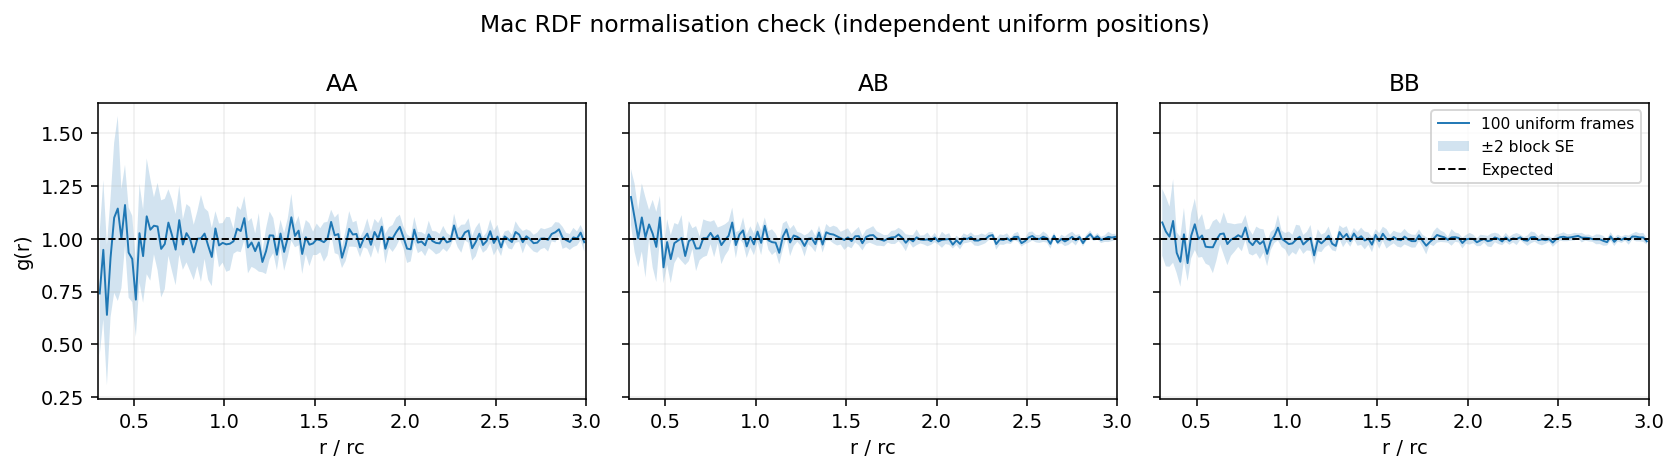

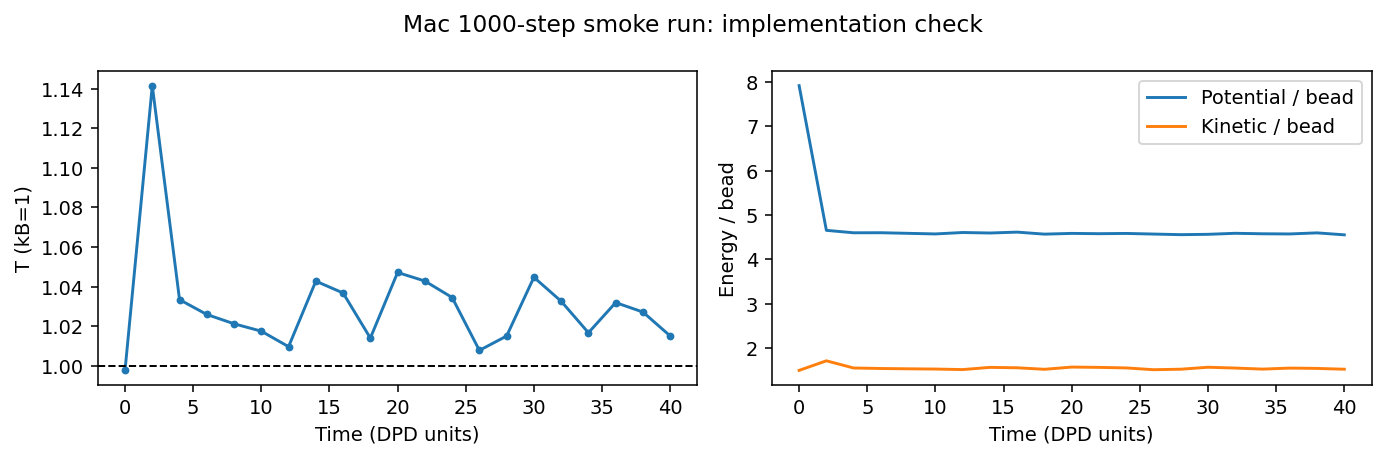

In [2]:
rdf = np.genfromtxt("data/a_uniform_rdf_blocks.csv", delimiter=",", names=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, pair in zip(axes, ("AA", "AB", "BB")):
    blocks = np.array([rdf["g_" + pair][rdf["block"] == b]
                       for b in np.unique(rdf["block"])])
    r = rdf["r"][rdf["block"] == 0]
    mean = blocks.mean(axis=0)
    sem = blocks.std(axis=0, ddof=1) / np.sqrt(len(blocks))
    keep = r >= 0.3
    ax.plot(r[keep], mean[keep], lw=1, label="100 uniform frames")
    ax.fill_between(r[keep], (mean-2*sem)[keep], (mean+2*sem)[keep],
                    alpha=.2, label="±2 block SE")
    ax.axhline(1, color="black", ls="--", lw=1, label="Expected")
    ax.set(title=pair, xlabel="r / rc", xlim=(.3, 3))
    ax.grid(alpha=.2)
axes[0].set_ylabel("g(r)")
axes[-1].legend(fontsize=8)
fig.suptitle("Mac RDF normalisation check (independent uniform positions)")
fig.tight_layout()
plt.show()

thermo = np.genfromtxt("data/a_smoke_thermo.csv", delimiter=",", names=True)
assert all(np.isfinite(thermo[name]).all() for name in thermo.dtype.names)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(thermo["time"], thermo["T"], marker=".")
axes[0].axhline(1, color="black", ls="--", lw=1)
axes[0].set(xlabel="Time (DPD units)", ylabel="T (kB=1)")
axes[1].plot(thermo["time"], thermo["Epot"]/3000, label="Potential / bead")
axes[1].plot(thermo["time"], thermo["Ekin"]/3000, label="Kinetic / bead")
axes[1].set(xlabel="Time (DPD units)", ylabel="Energy / bead")
axes[1].legend()
fig.suptitle("Mac 1000-step smoke run: implementation check")
fig.tight_layout()
plt.show()
print(f"Final smoke temperature: {thermo['T'][-1]:.5f}; all saved values finite.")
print("The short trace does not establish equilibration or timestep accuracy; B1–B3 remain to do.")

summary = np.genfromtxt("data/a_uniform_rdf.csv", delimiter=",", names=True)
keep = summary["r_lo"] >= 0.5
shell = (4*np.pi/3) * (summary["r_hi"][keep]**3 - summary["r_lo"][keep]**3)
for pair, count_pairs, expected in zip(("AA", "AB", "BB"),
                                      (150*149/2, 150*350, 350*349/2),
                                      (1.00097653, 0.999822139, 0.999230453)):
    integrated = summary["count_"+pair][keep].sum() / (100*count_pairs*shell.sum()/1000)
    assert np.isclose(integrated, expected, rtol=0, atol=1e-8)
    print(f"Mac integrated g_{pair}, 0.5 <= r < 3: {integrated:.9f}")


## Part B: Verification for monomers (N = 1)

*In the oral you should be able to:* say which bug classes each of these
three tests isolates, and why together they cover the code; derive the
conservative pair potential; explain why the energy-conservation run
needs a smaller timestep than a thermostatted run.

These three tests are designed to be run with parts of the physics
switched off, which is what makes them sharp: each isolates one layer of
the implementation. All three use the cubic box of side 10 with 3000
monomers and $a = 25$ (see the run plan).

### B1) Energy conservation

Derive the potential energy expression belonging to the conservative pair
force. Disable the dissipative and random interactions and verify
conservation of total energy.

Start these runs from an equilibrated state: the restart file written at
the end of the thermostatted monomer-fluid run, as you used restart files
in A2. Your initial positions are random, and their overlaps release so
much potential energy that a run without the thermostat heats itself to
well above $k_BT = 1$: still a test of energy conservation, but not of the
state you simulate everywhere else.

Deliver:

- the derivation of $U^C(r)$ from $\mathbf{F}^C$, and its value at
  $r = 0$;
- a **figure** of total, kinetic and potential energy against time for
  the conservative-only run;
- a **table** of the relative energy drift for at least three time steps
  ($\Delta t$ = 0.04, 0.02, 0.01, 0.005 are suggested), each run to the
  same physical time, with the observed scaling stated. Do not be alarmed
  if the largest time step does not conserve energy at all: say what you
  see, and explain why this run needs a smaller $\Delta t$ than your
  thermostatted production runs do.

*Results (B1):* …

### B1 — Energy conservation

The conservative pair force is $F^C(r)=a(1-r/r_c)$ for $r<r_c$. Using $F^C=-dU^C/dr$ and choosing $U^C(r_c)=0$ gives

$$
U^C(r)=
\begin{cases}
\dfrac{a r_c}{2}(1-r/r_c)^2, & r<r_c,\\
0, & r\geq r_c.
\end{cases}
$$

Therefore, $U^C(0)=12.5$ for $a=25$ and $r_c=1$.

Dissipative and random forces were disabled, while conservative forces remained enabled. All runs started from the same equilibrated thermostatted-fluid restart and reached the same physical time, $t=200$. This avoids the strong initial heating associated with randomly placed, overlapping particles.

The energy figure shows kinetic, potential and total energy for $\Delta t=0.01$. Kinetic and potential energy fluctuate through energy exchange, while their sum remains approximately constant. Relative drift was calculated as $\epsilon(t)=[E(t)-E(0)]/|E(0)|$.

| Δt | Steps | Final drift (%) | Maximum absolute error (%) |
|---:|---:|---:|---:|
| 0.04 | 5,000 | +3.59264 | 3.61118 |
| 0.02 | 10,000 | +0.14965 | 0.15867 |
| 0.01 | 20,000 | −0.00984 | 0.01486 |
| 0.005 | 40,000 | −0.00282 | 0.00435 |

The largest timestep produces substantial secular heating. Reducing the timestep improves conservation strongly. The maximum error scales approximately as $\Delta t^{2.59}$ over the three smallest timesteps; the smallest-pair exponent is 1.77, approaching the expected second-order behaviour. The complete range does not follow a single exact quadratic scaling.

A smaller timestep is needed here because numerical energy errors accumulate without a thermostat. In thermostatted runs, dissipative forces can remove numerical heating, so a stable temperature alone does not establish accurate integration. This test checks the conservative force–potential relation, neighbour-list implementation and integration accuracy.

![Kinetic, potential and total energy](data/B1_energy.png)

![Relative energy drift and timestep scaling](data/B1_drift.png)

### B2) Ideal-gas structure

Disable the conservative interactions, keeping the dissipative and random
forces on. The beads then interact only through friction and noise, so
their equilibrium structure must be that of an ideal gas.

Deliver a **figure** of $g(r)$ for this run, showing it is flat and equal
to 1 within the noise, and a sentence on what a *non*-flat result would
have told you (this test catches both a broken $g(r)$ normalisation and a
conservative force that is not really off).

### B3) Velocity statistics

Verify that the velocity distribution matches the imposed temperature
(Maxwellian, with the correct variance), independent of the conservative
interactions.

Deliver:

- a **figure** of the velocity histogram with the Maxwell-Boltzmann
  prediction on top, for a run with the conservative force on and one
  with it off;
- a **table** of the measured $k_BT$ from the variance in both cases,
  next to the imposed value, and a sentence comparing the deviation you
  find with what Groot and Warren report for the Verlet scheme with
  $\lambda = 1/2$ at $\Delta t = 0.04$ (Fig. 1 and the text beside it);
- a short statement of what this verifies about your $\sigma$ and
  $\gamma$: if you had used a wrong fluctuation-dissipation relation,
  what would this table look like?

### B2 — Ideal-gas structure

Conservative forces were disabled while dissipative and random forces remained enabled. With no conservative potential, equilibrium positions should be uniformly distributed, giving $g(r)=1$. The particles still interact dynamically through friction and noise.

The AA, AB and BB RDFs were calculated using exact shell volumes and finite-system pair counts. After discarding 5000 equilibration steps, 300 frames were sampled and divided into 15 blocks for uncertainty estimates.

The RDF figure is approximately flat at one for all pair types. Shell-volume-weighted averages over $0.3\leq r\leq3$ are 0.999757 (AA), 0.999927 (AB) and 0.999990 (BB), with block standard errors of 0.000134, 0.000163 and 0.000190, respectively. Small-distance bins are noisier because their shell volumes contain fewer pairs.

A systematic non-flat result would suggest incorrect RDF counting/normalization or conservative interactions that were not fully disabled. This test therefore checks both the RDF implementation and the conservative-force switch.

![Ideal-gas partial RDFs](data/B2_ideal_rdf.png)


### B3 — Velocity statistics

Completed-step velocities were sampled with conservative forces both enabled and disabled, while keeping the DPD thermostat active. At equilibrium, each Cartesian velocity component should follow

$$
p(v_\alpha)=\sqrt{\frac{m}{2\pi k_BT}}
\exp\left(-\frac{m v_\alpha^2}{2k_BT}\right),
\qquad
\operatorname{Var}(v_\alpha)=\frac{k_BT}{m}.
$$

The speed $s=|\mathbf v|$ instead follows the Maxwell distribution,

$$
p(s)=4\pi s^2
\left(\frac{m}{2\pi k_BT}\right)^{3/2}
\exp\left(-\frac{m s^2}{2k_BT}\right).
$$

The figure compares normalized component and speed histograms with predictions using both the imposed temperature and the measured temperature. Both conservative-force settings produce approximately Maxwellian distributions, although their widths are slightly larger than predicted at the imposed temperature.

Temperature was calculated from unbinned component variances:

$$
k_BT_{\mathrm{var}}=
\frac{m}{3}
\left[\operatorname{Var}(v_x)+\operatorname{Var}(v_y)+\operatorname{Var}(v_z)\right].
$$

| Conservative forces | Imposed $k_BT$ | Measured $k_BT_{\mathrm{var}}$ | Block standard error | Deviation |
|---|---:|---:|---:|---:|
| On | 1.00000 | 1.02848 | 0.00097 | +2.85% |
| Off | 1.00000 | 1.03124 | 0.00084 | +3.12% |

Because total momentum is constrained, multiplying by $N/(N-1)$ gives the corresponding degrees-of-freedom-corrected temperatures: 1.02882 and 1.03158 for $N=3000$. This small correction does not explain the approximately 3% heating.

Groot and Warren report approximately 2% heating for Verlet with $\lambda=1/2$ at $\Delta t=0.04$. Our few-percent deviations are qualitatively consistent with this finite-timestep bias, although their reference density is 4 rather than our 3.

These results support the thermostat implementation and show approximately Maxwellian velocity statistics in both conservative systems. They also reveal finite-step temperature error. The required fluctuation–dissipation conditions are $\sigma^2=2\gamma k_BT$ and $w_D=w_R^2$. With correct weights but incorrect amplitudes, both systems would tend towards the wrong temperature, $k_BT_{\mathrm{effective}}=\sigma^2/(2\gamma)$, and their histogram widths would disagree with the imposed prediction.

![Velocity and speed distributions with Maxwell–Boltzmann predictions](data/B3_velocity.png)

*Results (B2, B3):* …

In [4]:
# B2/B3: flat g(r); velocity histogram against Maxwell-Boltzmann

## Part C: Validation for monomers (N = 1)

*In the oral you should be able to:* say what agreement with a published
simulation result does and does not validate; explain how χ is measured
from composition profiles and what must be true of the profiles first;
explain the sign, magnitude and factor of two of your surface tension.

**Every demixing run** (C2, C3, C4, and Part D) uses the same geometry.
The box is $20 \times 10 \times 10$, elongated along $x$, with 6000
beads, and starts with A in the half $x < 10$ and B in the half
$x > 10$. The two phases then form two flat slabs with **two flat
interfaces perpendicular to $x$**, and the two bulk regions are wide
enough to read a composition from. In a cubic box the system can
separate along any axis, or not into flat slabs at all, and then
neither the composition profile nor the surface tension means anything.
Groot and Warren elongate their box along $z$; we use $x$ throughout, so
read their $z$ as our $x$.

The **composition profile** is the number density of A and of B in thin
slabs perpendicular to $x$ (a bin width of about 0.2 to 0.5), averaged
over the run after equilibration, and the A fraction
$\phi_A(x) = \rho_A / (\rho_A + \rho_B)$ computed from them. Write it out
in blocks during the run (every few thousand steps), not only once at
the end: C2 asks when the profile became steady, and the error estimates
of C3 come from the scatter between blocks.

### C1) Radial distribution function

Reproduce the $g(r)$ of Fig. 2 ($\rho = 3$, $a = 25$).

Deliver a **figure** with your $g(r)$ and the published curve on the same
axes (digitise a few points from the figure if you have no data file),
and a sentence on where they agree and where they do not. State your run
length and how you know $g(r)$ has converged.

### C1 — Radial distribution function

The monomer fluid was simulated at $\rho=3$, $a_{AA}=a_{AB}=a_{BB}=25$ and imposed $k_BT=1$, with conservative and DPD thermostat forces enabled. The run used 120,000 steps at $\Delta t=0.04$, corresponding to a total time of 4800. The first 20,000 steps were discarded, leaving 100,000 production steps, 2000 sampled configurations and 20 blocks.

The RDF figure overlays the all-pair simulation RDF with the digitized curve from Groot and Warren’s Fig. 2. Agreement is good over the supplied reference range, approximately $0.17\leq r/r_c\leq0.99$. The RMSE is 0.00595. The largest signed difference is −0.01176 at $r/r_c=0.67145$, where the simulation lies slightly below the reference. These small differences may include digitization, finite-size and numerical effects; they should not be attributed entirely to sampling noise.

The RDF has the expected liquid structure: close pairs are strongly suppressed by soft repulsion, a first-neighbour peak occurs near $r/r_c\approx0.85$, and weak oscillations decay towards $g(r)=1$. The finite DPD potential makes overlap energetically costly without imposing a strict hard core. Structural correlations can extend beyond the interaction cutoff.

Convergence was assessed by comparing the first and second production halves. Their curves nearly overlap, with an RMS difference of 0.00127. Estimated standard errors remain of comparable magnitude when the block length increases from 5000 to 10,000 and 20,000 steps, without a clear systematic increase. This supports a stationary, well-sampled RDF, although the largest block size leaves only five blocks and therefore a noisier uncertainty estimate.

The required deliverables are the simulation/reference RDF overlay, the agreement assessment, the stated run length and the convergence evidence. The RDF and convergence figures provide these. Agreement supports the equilibrium pair structure at this state; it does not independently validate transport properties or demixing.


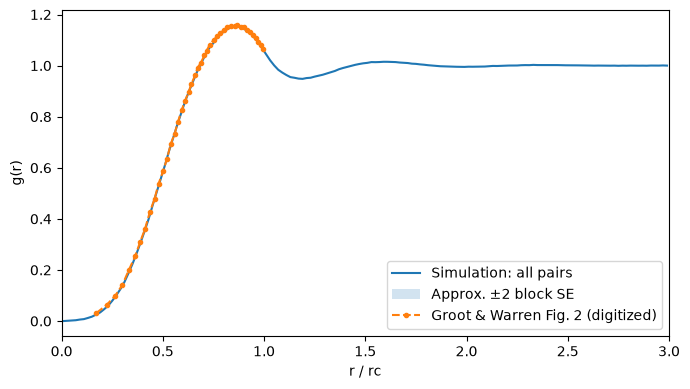

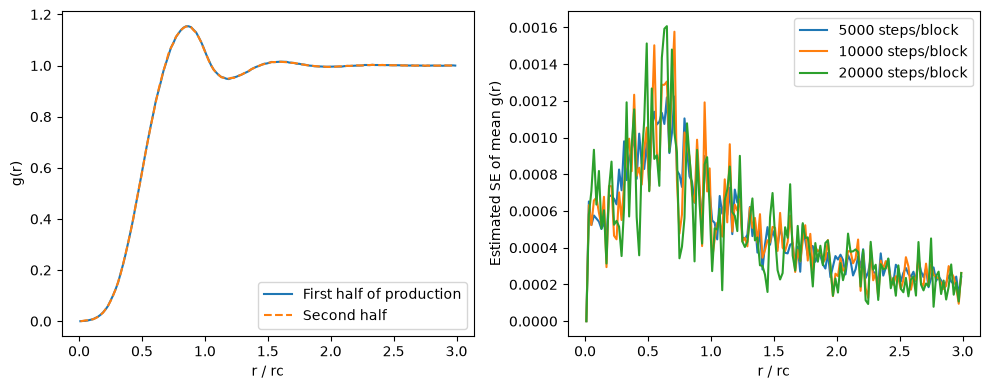

{'total_steps': 120000,
 'discard_steps': 20000,
 'production_steps': 100000,
 'total_time': 4800.0,
 'production_frames': 2000,
 'blocks': 20,
 'reference_RMSE_over_digitized_range': 0.005948588848262287,
 'largest_reference_difference_r': 0.6714507097246712,
 'largest_reference_difference': -0.011758750974929066,
 'first_vs_second_half_RMS_difference': 0.0012678623874690714}

Assess convergence from overlapping first/second-half curves and stable SE on reblocking.
Describe agreement over the digitized range only (the supplied reference ends near r=1).
Agreement validates this equilibrium structure at these conditions; it does not validate every force, transport property, or timestep.


In [5]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = Path.cwd()                 # folder containing A3.ipynb, code/, data/
DATA = ROOT / 'data'
TAG = 'c1'
REFERENCE = DATA / 'reference' / 'Groot_fig2_fitteddaata.csv'
m = json.loads((DATA / f'{TAG}_manifest.json').read_text())
rdf = np.atleast_1d(np.genfromtxt(DATA / f'{TAG}_rdf.csv', delimiter=',', names=True))
b = np.atleast_1d(np.genfromtxt(DATA / f'{TAG}_rdf_blocks.csv', delimiter=',', names=True))
ids = np.unique(b['block'])
N = m['num_part']; NA = N // 2; NB = N - NA
weights = np.array([NA*(NA-1), 2*NA*NB, NB*(NB-1)]) / (N*(N-1))
def pooled(rows):
    return np.column_stack([rows['g_AA'], rows['g_AB'], rows['g_BB']]) @ weights
r = rdf['r']; blocks = np.array([pooled(b[b['block']==i]) for i in ids])
frames = np.array([b[b['block']==i]['frames'][0] for i in ids])
assert len(ids)>=8 and np.all(frames==frames[0]), 'Use at least 8 equal production blocks.'
g = pooled(rdf)
assert np.allclose(g, blocks.mean(axis=0), atol=1e-8)
se = blocks.std(axis=0, ddof=1)/np.sqrt(len(ids))
ref = np.loadtxt(REFERENCE, delimiter=',')  # no header; columns r, g(r)
ref = ref[np.argsort(ref[:,0])]
interp = np.interp(ref[:,0], r, g)
mask = (ref[:,0]>=r.min()) & (ref[:,0]<=r.max())
rmse = float(np.sqrt(np.mean((interp[mask]-ref[mask,1])**2)))
worst = int(np.flatnonzero(mask)[np.argmax(np.abs(interp[mask]-ref[mask,1]))])
half = len(ids)//2
first, last = blocks[:half].mean(axis=0), blocks[half:].mean(axis=0)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(r,g,label='Simulation: all pairs');ax.fill_between(r,g-2*se,g+2*se,alpha=.2,label='Approx. ±2 block SE')
ax.plot(ref[:,0],ref[:,1],'o--',ms=3,label='Groot & Warren Fig. 2 (digitized)')
ax.set(xlabel='r / rc',ylabel='g(r)',xlim=(0,3));ax.legend();fig.tight_layout()
fig.savefig(DATA/'C1_RDF.png',dpi=200);plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(r,first,label='First half of production');axes[0].plot(r,last,'--',label='Second half')
axes[0].set(xlabel='r / rc',ylabel='g(r)');axes[0].legend()
for q in [1,2,4]:
    nb=len(ids)//q
    if nb>=4:
        merged=blocks[:nb*q].reshape(nb,q,len(r)).mean(axis=1)
        axes[1].plot(r,merged.std(axis=0,ddof=1)/np.sqrt(nb),label=f'{q*m["block"]} steps/block')
axes[1].set(xlabel='r / rc',ylabel='Estimated SE of mean g(r)');axes[1].legend()
fig.tight_layout();fig.savefig(DATA/'C1_convergence.png',dpi=200);plt.show()
summary={'total_steps':m['steps'],'discard_steps':m['equil'],'production_steps':m['steps']-m['equil'],
         'total_time':m['steps']*m['dt'],'production_frames':int(rdf['frames'][0]),'blocks':len(ids),
         'reference_RMSE_over_digitized_range':rmse,'largest_reference_difference_r':float(ref[worst,0]),
         'largest_reference_difference':float(interp[worst]-ref[worst,1]),
         'first_vs_second_half_RMS_difference':float(np.sqrt(np.mean((first-last)**2)))}
(DATA/'C1_summary.json').write_text(json.dumps(summary,indent=2));display(summary)
print('Assess convergence from overlapping first/second-half curves and stable SE on reblocking.')
print('Describe agreement over the digitized range only (the supplied reference ends near r=1).')
print('Agreement validates this equilibrium structure at these conditions; it does not validate every force, transport property, or timestep.')

### C2) Binary demixing

Reproduce the phase separation of Fig. 6, using the parameters in its
caption ($a_{AB} = 37$) and the geometry above.

Deliver:

- a **snapshot** of the demixed system (OVITO, beads coloured by type);
- a **figure** of the composition profile along $x$, showing the two
  bulk plateaus and the two interfaces;
- a statement of how long the run needed to reach a steady profile, and
  how you decided it had.

### C2 — Binary demixing

The binary monomer system was simulated with $a_{AA}=a_{BB}=25$ and $a_{AB}=37$, at $\rho=3$ and imposed $k_BT=1$. The elongated periodic box was $20\times10\times10$, containing 6000 beads. A and B initially occupied opposite halves along $x$. Conservative and DPD thermostat forces remained enabled.

The stronger repulsion between unlike particles favours demixing by reducing AB contacts. The OVITO snapshot shows two compositionally distinct slabs, consistent with the density and composition profiles. Each phase retains a small minority population because thermal mixing competes with segregation.

![OVITO snapshot of the demixed system](data/C2_ovito.png)

The density figure reproduces the main features of Groot and Warren’s Fig. 6: two nearly homogeneous bulk plateaus, smooth interfacial transitions and a small dip in the total density near each interface. The A, B and total-density curves agree closely with the digitized reference after a small periodic translation of 0.02494 length units. This translation accounts for the arbitrary position of the interfaces.

The minority A fraction in the B-rich bulk is 0.04058, while the minority B fraction in the A-rich bulk is 0.04071. Their close agreement is consistent with the symmetry of the interaction parameters. The corresponding majority fractions are approximately 0.9594 and 0.9593.

There are two interfaces: one near $x=10$ and another across the periodic $x=0/20$ boundary. The two boundary edges represent the same periodic interface.

![Density profiles compared with Fig. 6](data/C2_density.png)

The simulation ran for 120,000 steps at $\Delta t=0.04$, reaching $t=4800$. Data before $t=800$ (20,000 steps) were discarded, leaving 100,000 production steps.

The rolling-profile diagnostic identifies a candidate steady time of $t=600$, corresponding to 15,000 steps. The profile history shows persistent bulk regions and interfaces, and the aligned and laboratory-frame averages have similar plateau values, with small differences near the interfaces.

However, the minority-fraction histories show substantial fluctuations and a tendency towards larger values late in the run. Thus, $t=600$ indicates approximate stability of the overall profile rather than definitive convergence of the precise bulk compositions. Comparing production-half means with block uncertainties is needed to distinguish slow relaxation from correlated fluctuations.

![Composition profiles and bulk-fraction histories](data/C2_composition_convergence.png)

![Time evolution of the composition profile](data/C2_profile_history.png)

The OVITO snapshot, density/composition figures and time-history diagnostics provide the requested snapshot, two-phase profile and assessment of the time needed to approach a steady profile. The results support successful reproduction of the qualitative phase separation in Fig. 6, with the convergence qualification above.

Cutoff t=800; 20 retained blocks; first/second-half bulk difference=0.005945; combined SE=0.00253
Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks): 600.0


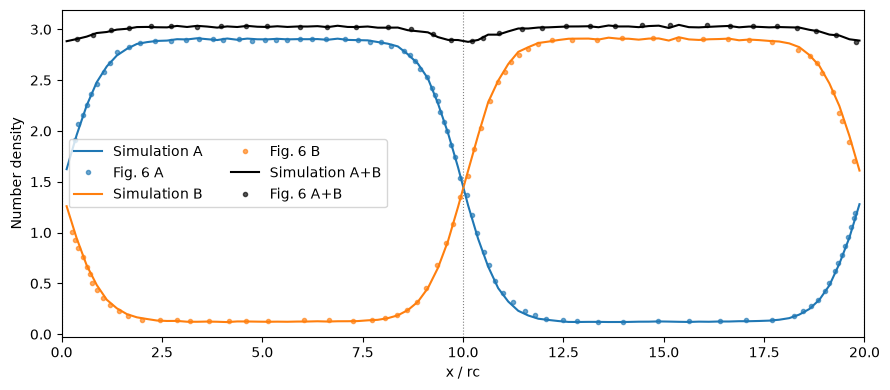

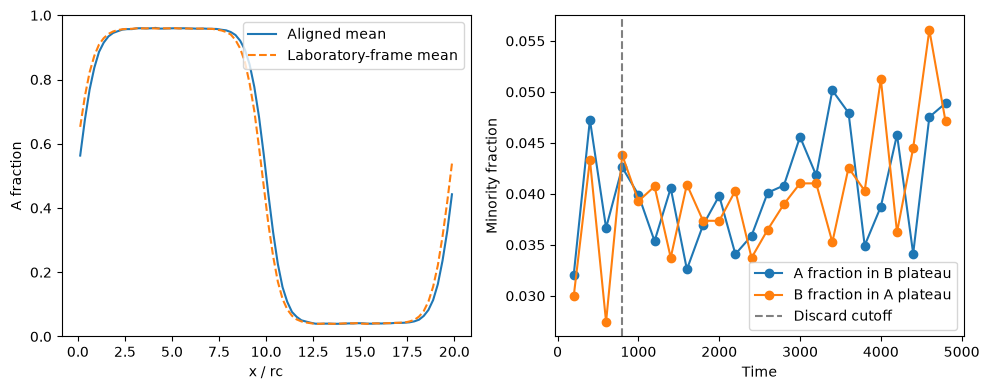

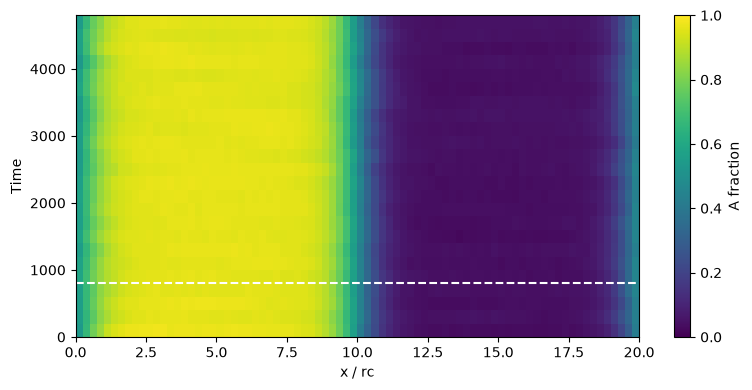

{'total_steps': 120000,
 'total_time': 4800.0,
 'discard_time': 800.0,
 'candidate_steady_time': 600.0,
 'reference_translation': 0.024937655860348684,
 'minority_A_in_B': 0.04057983149033847,
 'minority_B_in_A': 0.04071275536385034}

Two interfaces: one near x=Lx/2, the other at the periodic x=0/Lx boundary.
Confirm persistent flat plateaus and stable blocks before declaring equilibrium. The threshold is only a diagnostic.
For your OVITO snapshot open data/c2.pdb: visualization labels C=A, O=B; use the final equilibrated frame.


In [6]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = Path.cwd()
DATA = ROOT / 'data'

def csv(name):
    return np.atleast_1d(np.genfromtxt(DATA/name,delimiter=',',names=True,dtype=None,encoding='utf-8'))

def sem_reblock(values):
    """Report SE versus block size; retain the largest supported estimate."""
    v=np.asarray(values,float)
    if len(v)<4: raise ValueError('Need at least four production blocks; run longer.')
    out=[]
    for q in [1,2,4]:
        nb=len(v)//q
        if nb>=4:
            z=v[:nb*q].reshape(nb,q).mean(axis=1)
            out.append((q,nb,float(z.std(ddof=1)/np.sqrt(nb))))
    return max(z[2] for z in out),out

def profiles(tag,discard_time=None):
    m=json.loads((DATA/f'{tag}_manifest.json').read_text())
    raw=csv(f'{tag}_profile_blocks.csv');ids=np.unique(raw['block'])
    groups=[raw[raw['block']==i] for i in ids]
    assert len({len(g) for g in groups})==1
    assert np.all([np.allclose(g['x'],groups[0]['x']) for g in groups])
    assert len({int(g['frames'][0]) for g in groups})==1, 'Use equal full blocks.'
    x=groups[0]['x'];ra=np.array([g['rho_A'] for g in groups]);rb=np.array([g['rho_B'] for g in groups])
    la=np.array([g['rho_A_lab'] for g in groups]);lb=np.array([g['rho_B_lab'] for g in groups])
    start=np.array([g['t_start'][0] for g in groups]);end=np.array([g['t_end'][0] for g in groups])
    cut=m['equil']*m['dt'] if discard_time is None else discard_time
    keep=start>=cut-1e-9
    L=m['L'][0];windowA=(x>=.2*L)&(x<.3*L);windowB=(x>=.7*L)&(x<.8*L)
    phi=ra/(ra+rb)
    minorityAinB=ra[:,windowB].sum(axis=1)/(ra[:,windowB]+rb[:,windowB]).sum(axis=1)
    minorityBinA=rb[:,windowA].sum(axis=1)/(ra[:,windowA]+rb[:,windowA]).sum(axis=1)
    # Conservation: density integrals must recover NA=NB=N/2 per block.
    dx=m['L'][0]/len(x);area=m['L'][1]*m['L'][2]
    assert np.allclose(ra.sum(axis=1)*dx*area,m['num_part']/2)
    assert np.allclose(rb.sum(axis=1)*dx*area,m['num_part']/2)
    return dict(m=m,x=x,ra=ra,rb=rb,la=la,lb=lb,phi=phi,start=start,end=end,keep=keep,cut=cut,
                bphi=minorityAinB,aphi=minorityBinA,order=np.array([g['order'][0] for g in groups]),
                aligned=np.array([g['aligned_fraction'][0] for g in groups]),windowA=windowA,windowB=windowB)

def steady_candidate(d):
    """Exploratory tolerance diagnostic, not a proof of stationarity."""
    z=d['phi'];window=3
    if len(z)<2*window:return None
    target=z[-window:].mean(axis=0)
    dist=np.array([np.sqrt(np.mean((z[i-window+1:i+1].mean(axis=0)-target)**2))
                   for i in range(window-1,len(z))])
    for j in range(len(dist)-window+1):
        if np.all(dist[j:]<.03):return float(d['end'][j+window-1])
    return None

def diagnose(d):
    keep=d['keep']; n=int(keep.sum())
    if n<4:raise ValueError('Too few retained blocks after the chosen discard time.')
    if np.any(d['aligned'][keep]<.95) and d['m']['aab']>25:
        print('CAUTION: some frames lack a strong x slab; inspect morphology before extracting bulk chi.')
    vals=d['bphi'][keep];half=n//2
    e1,_=sem_reblock(vals[:half]) if half>=4 else (float('nan'),[])
    e2,_=sem_reblock(vals[half:]) if n-half>=4 else (float('nan'),[])
    drift=abs(vals[:half].mean()-vals[half:].mean())
    print(f'Cutoff t={d["cut"]:g}; {n} retained blocks; first/second-half bulk difference={drift:.4g}; combined SE={np.hypot(e1,e2):.4g}')
    print('Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks):',steady_candidate(d))
    return drift,float(np.hypot(e1,e2))
# %% C2 settings: rerun with a later cutoff if convergence diagnostics require it.
TAG='c2'
DISCARD_TIME=None  # None uses the C run's equilibration setting; alternatively e.g. 1600.0
REFERENCE_SHIFT=None  # None finds a periodic translation for the digitized curves.
d=profiles(TAG,DISCARD_TIME);diagnose(d)
k=d['keep'];x=d['x'];L=d['m']['L'][0]
A=d['ra'][k].mean(axis=0);B=d['rb'][k].mean(axis=0)
refs={s:np.loadtxt(DATA/'reference'/f'Groot_fig6_{s}.csv',delimiter=',') for s in ['A','B','AB']}
# AB is the total-density curve; verified from the supplied values near rho=3.
if REFERENCE_SHIFT is None:
    shifts=np.linspace(-L/2,L/2,401,endpoint=False)
    scores=[sum(np.mean((np.interp((refs[s][:,0]+shift)%L,x,v,period=L)-refs[s][:,1])**2)
                for s,v in [('A',A),('B',B)]) for shift in shifts]
    REFERENCE_SHIFT=float(shifts[np.argmin(scores)])
fig,ax=plt.subplots(figsize=(9,4))
for s,v,color in [('A',A,'tab:blue'),('B',B,'tab:orange'),('AB',A+B,'black')]:
    ax.plot(x,v,color=color,label='Simulation '+('A+B' if s=='AB' else s))
    xx=(refs[s][:,0]+REFERENCE_SHIFT)%L;idx=np.argsort(xx)
    ax.plot(xx[idx],refs[s][idx,1],'.',color=color,alpha=.65,label='Fig. 6 '+('A+B' if s=='AB' else s))
for v in [0,L/2,L]:ax.axvline(v,color='grey',ls=':',lw=.8)
ax.set(xlabel='x / rc',ylabel='Number density',xlim=(0,L));ax.legend(ncol=2);fig.tight_layout()
fig.savefig(DATA/'C2_density.png',dpi=200);plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
phi=d['phi'][k];axes[0].plot(x,A/(A+B),label='Aligned mean')
labA=d['la'][k].mean(axis=0);labB=d['lb'][k].mean(axis=0)
axes[0].plot(x,labA/(labA+labB),'--',label='Laboratory-frame mean')
axes[0].set(xlabel='x / rc',ylabel='A fraction',ylim=(0,1));axes[0].legend()
axes[1].plot(d['end'],d['bphi'],'o-',label='A fraction in B plateau')
axes[1].plot(d['end'],d['aphi'],'o-',label='B fraction in A plateau')
axes[1].axvline(d['cut'],color='grey',ls='--',label='Discard cutoff')
axes[1].set(xlabel='Time',ylabel='Minority fraction');axes[1].legend();fig.tight_layout()
fig.savefig(DATA/'C2_composition_convergence.png',dpi=200);plt.show()
fig,ax=plt.subplots(figsize=(8,4));im=ax.imshow(d['phi'],origin='lower',aspect='auto',extent=[0,L,0,d['end'][-1]],vmin=0,vmax=1)
fig.colorbar(im,ax=ax,label='A fraction');ax.axhline(d['cut'],color='white',ls='--');ax.set(xlabel='x / rc',ylabel='Time')
fig.tight_layout();fig.savefig(DATA/'C2_profile_history.png',dpi=200);plt.show()
se=phi.std(axis=0,ddof=1)/np.sqrt(k.sum())
np.savetxt(DATA/'C2_profile_table.csv',np.column_stack([x,A,B,A/(A+B),se]),delimiter=',',header='x,rho_A,rho_B,phi_A,phi_block_SE',comments='')
summary={'total_steps':d['m']['steps'],'total_time':d['m']['steps']*d['m']['dt'],
         'discard_time':d['cut'],'candidate_steady_time':steady_candidate(d),'reference_translation':REFERENCE_SHIFT,
         'minority_A_in_B':float(d['bphi'][k].mean()),'minority_B_in_A':float(d['aphi'][k].mean())}
(DATA/'C2_summary.json').write_text(json.dumps(summary,indent=2));display(summary)
print('Two interfaces: one near x=Lx/2, the other at the periodic x=0/Lx boundary.')
print('Confirm persistent flat plateaus and stable blocks before declaring equilibrium. The threshold is only a diagnostic.')
print('For your OVITO snapshot open data/c2.pdb: visualization labels C=A, O=B; use the final equilibrated frame.')

### C3) Measuring the χ-parameter

Measure χ with Eq. (18) from the composition profiles of demixed runs at
$\rho = 3$, for this edition's series

$$a_{AB} \in \{35,\ 39,\ 43,\ 47\}, \qquad a_{AA} = a_{BB} = 25 .$$

For monomers $N_A = 1$, and $\phi_A$ in Eq. (18) is the A fraction in the
bulk of the B-rich phase. Read it from the plateau of the profile, away
from both interfaces.

Deliver:

- a **figure** with the four composition profiles;
- a **table** of the bulk compositions and the resulting χ per $a_{AB}$,
  each with an error estimate;
- a **figure** of χ against $\Delta a = a_{AB} - a_{AA}$ with a linear
  fit, the fitted slope stated, and the slope of Eq. (24) (Fig. 7) for
  comparison. Groot and Warren fit only the points with $\chi > 3$
  (p. 4429), with the same integrator and $\Delta t$ as yours: compare
  like with like, and report the fit over all four points as well.

Then state what must be true of the profiles before Eq. (18) may be
applied at all, and confirm that it is true of yours.

### C3 — Measuring the χ-parameter

Four monomer mixtures were simulated at $\rho=3$, with $a_{AA}=a_{BB}=25$ and $a_{AB}=35,39,43,47$. Each run used the elongated $20\times10\times10$ periodic box, initially separated A/B slabs, and the Verlet scheme with $\lambda=1/2$ and $\Delta t=0.04$.

Each simulation reached $t=4800$. Samples before $t=800$ were discarded, leaving 20 production blocks. The minority A fraction was measured in the B-rich bulk plateau, using the registered window $14\leq x<16$, away from both interfaces.

For monomers, Eq. (18) gives

$$
\chi=\frac{\ln[(1-\phi_A)/\phi_A]}{1-2\phi_A}.
$$

Here $\phi_A$ is the A fraction in the B-rich plateau, rather than the overall A fraction of 0.5. Composition standard errors were estimated using reblocking, and χ standard errors using a block jackknife.

| aAB | Delta a | A fraction in B | Composition SE | Chi | Chi SE |
|---:|---:|---:|---:|---:|---:|
| 35 | 10 | 0.100587 | 0.00353432 | 2.74242 | 0.0248733 |
| 39 | 14 | 0.021541 | 0.000973914 | 3.98782 | 0.0402293 |
| 43 | 18 | 0.00566255 | 0.000563703 | 5.22740 | 0.0990145 |
| 47 | 22 | 0.00256082 | 0.000321966 | 5.99557 | 0.124277 |

Increasing AB repulsion produces stronger segregation: the minority concentration decreases, the interfaces narrow, and χ increases. This is expected because unlike contacts become increasingly costly. The relative uncertainty in the minority concentration becomes larger at stronger segregation, where fewer minority particles are available for sampling.

![Composition profiles and selected bulk windows](data/C3_profiles.png)

Eq. (18) requires steady two-phase coexistence and homogeneous bulk plateaus sufficiently far from the interfaces. These conditions are supported by the visible plateaus and bulk-composition histories. The rolling-profile diagnostic gives a candidate steady time of $t=600$ for each case, before the discard cutoff.

The first/second-half bulk-composition differences are approximately 1.55, 0.81, 1.71 and 0.36 combined standard errors for increasing $a_{AB}$. None exceeds two combined standard errors, supporting consistency between the production halves. This does not prove that all slow correlations have disappeared; block-size and bulk-window sensitivity checks remain relevant.

![Bulk-composition histories](data/C3_bulk_convergence.png)

Weighted fits through the origin were performed for $\chi$ against $\Delta a=a_{AB}-25$:

- All four points: slope $0.2793\pm0.0017$.
- Only points with measured $\chi>3$: slope $0.2838\pm0.0023$.
- Groot and Warren, Eq. (24): slope $0.286\pm0.002$.

The all-point slope is approximately 2.3% below the published value and differs by about 2.6 combined standard errors. The restricted fit agrees within the combined uncertainty. This is the appropriate comparison with the paper, which fitted only $\chi>3$: the $a_{AB}=35$ point, with $\chi=2.74242$, is excluded from that fit.

The results support an approximately linear mapping between excess repulsion and χ. Including the weaker-segregation point changes the fitted slope, showing why the fitting range must be stated. The reported sampling errors do not include every possible finite-size, plateau-selection or model-mapping effect.

![χ versus excess repulsion, with both fits](data/C3_chi_fit.png)


Cutoff t=800; 20 retained blocks; first/second-half bulk difference=0.008215; combined SE=0.0053
Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks): 600.0
Cutoff t=800; 20 retained blocks; first/second-half bulk difference=0.001777; combined SE=0.002183
Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks): 600.0
Cutoff t=800; 20 retained blocks; first/second-half bulk difference=0.001649; combined SE=0.0009628
Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks): 600.0
Cutoff t=800; 20 retained blocks; first/second-half bulk difference=0.0001868; combined SE=0.0005171
Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks): 600.0


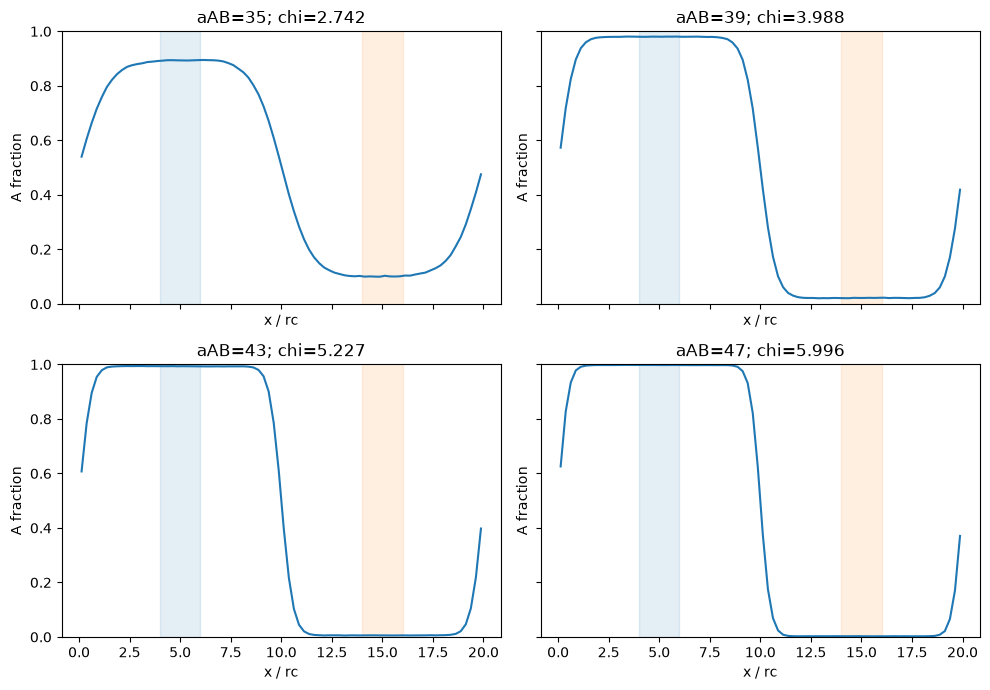

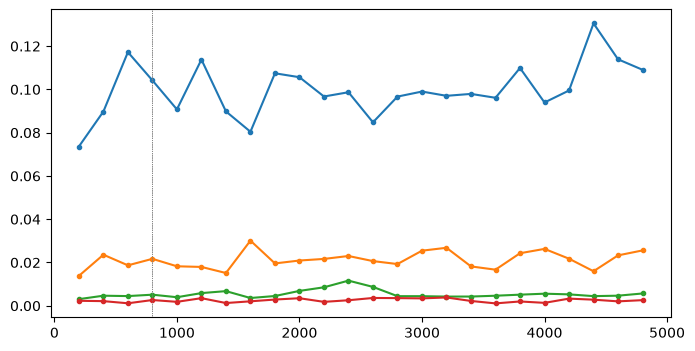

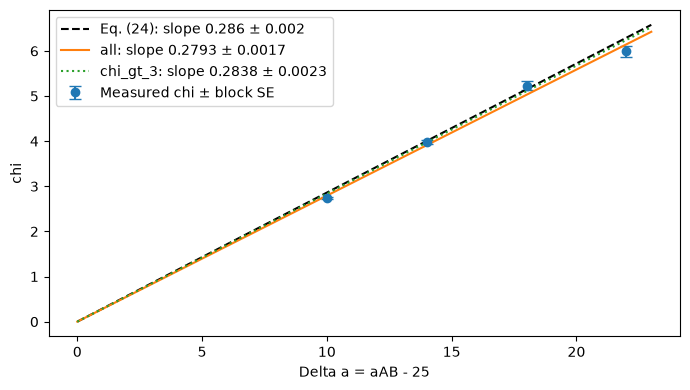

array([(35., 10., 0.1005872 , 0.00353432, 2.74242224, 0.0248733 , 0.10648036, 0.10257944, -1.99223589e-03, 6.43318530e-04, 800., 20.),
       (39., 14., 0.02154105, 0.00097391, 3.98782222, 0.0402293 , 0.01965041, 0.02149138,  4.96639176e-05, 3.01237993e-04, 800., 20.),
       (43., 18., 0.00566255, 0.0005637 , 5.2274035 , 0.09901445, 0.00648304, 0.00560873,  5.38134616e-05, 8.65767925e-05, 800., 20.),
       (47., 22., 0.00256082, 0.00032197, 5.99556996, 0.12427722, 0.00203134, 0.00256365, -2.82881256e-06, 9.19905267e-05, 800., 20.)],
      dtype=[('aAB', '<f8'), ('delta_a', '<f8'), ('phi_A_in_B', '<f8'), ('phi_SE', '<f8'), ('chi', '<f8'), ('chi_SE', '<f8'), ('phi_B_in_A', '<f8'), ('phi_wider_window', '<f8'), ('window_difference', '<f8'), ('window_difference_SE', '<f8'), ('discard_time', '<f8'), ('blocks', '<f8')])

array([('all', 'through_origin', 0.27932561, 0.00169729,  0.        , 0.        , 4, 13.3756909 ),
       ('all', 'free_intercept', 0.29405633, 0.00728219, -0.18213874, 0.0875612 , 4,  9.04874663),
       ('chi_gt_3', 'through_origin', 0.28375516, 0.00232186,  0.        , 0.        , 3,  5.55939365),
       ('chi_gt_3', 'free_intercept', 0.2654455 , 0.01461291,  0.28514163, 0.22468006, 3,  3.94877693)],
      dtype=[('subset', '<U8'), ('fit', '<U14'), ('slope', '<f8'), ('slope_SE', '<f8'), ('intercept', '<f8'), ('intercept_SE', '<f8'), ('n', '<i8'), ('weighted_residual_sum', '<f8')])

Check C3_profiles, C3_bulk_convergence and C3_reblocking before reporting final chi values.
Eq. (18) requires equilibrated coexisting phases, homogeneous bulk plateaus, symmetry, and monomers.
The first point may have chi<3; report it but compare the chi>3 fit to the paper separately.
Fit SE uses supplied sampling errors; residuals, finite-size bias and model departures are separate uncertainties.


In [7]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = Path.cwd()
DATA = ROOT / 'data'

def csv(name):
    return np.atleast_1d(np.genfromtxt(DATA/name,delimiter=',',names=True,dtype=None,encoding='utf-8'))

def sem_reblock(values):
    """Report SE versus block size; retain the largest supported estimate."""
    v=np.asarray(values,float)
    if len(v)<4: raise ValueError('Need at least four production blocks; run longer.')
    out=[]
    for q in [1,2,4]:
        nb=len(v)//q
        if nb>=4:
            z=v[:nb*q].reshape(nb,q).mean(axis=1)
            out.append((q,nb,float(z.std(ddof=1)/np.sqrt(nb))))
    return max(z[2] for z in out),out

def profiles(tag,discard_time=None):
    m=json.loads((DATA/f'{tag}_manifest.json').read_text())
    raw=csv(f'{tag}_profile_blocks.csv');ids=np.unique(raw['block'])
    groups=[raw[raw['block']==i] for i in ids]
    assert len({len(g) for g in groups})==1
    assert np.all([np.allclose(g['x'],groups[0]['x']) for g in groups])
    assert len({int(g['frames'][0]) for g in groups})==1, 'Use equal full blocks.'
    x=groups[0]['x'];ra=np.array([g['rho_A'] for g in groups]);rb=np.array([g['rho_B'] for g in groups])
    la=np.array([g['rho_A_lab'] for g in groups]);lb=np.array([g['rho_B_lab'] for g in groups])
    start=np.array([g['t_start'][0] for g in groups]);end=np.array([g['t_end'][0] for g in groups])
    cut=m['equil']*m['dt'] if discard_time is None else discard_time
    keep=start>=cut-1e-9
    L=m['L'][0];windowA=(x>=.2*L)&(x<.3*L);windowB=(x>=.7*L)&(x<.8*L)
    phi=ra/(ra+rb)
    minorityAinB=ra[:,windowB].sum(axis=1)/(ra[:,windowB]+rb[:,windowB]).sum(axis=1)
    minorityBinA=rb[:,windowA].sum(axis=1)/(ra[:,windowA]+rb[:,windowA]).sum(axis=1)
    # Conservation: density integrals must recover NA=NB=N/2 per block.
    dx=m['L'][0]/len(x);area=m['L'][1]*m['L'][2]
    assert np.allclose(ra.sum(axis=1)*dx*area,m['num_part']/2)
    assert np.allclose(rb.sum(axis=1)*dx*area,m['num_part']/2)
    return dict(m=m,x=x,ra=ra,rb=rb,la=la,lb=lb,phi=phi,start=start,end=end,keep=keep,cut=cut,
                bphi=minorityAinB,aphi=minorityBinA,order=np.array([g['order'][0] for g in groups]),
                aligned=np.array([g['aligned_fraction'][0] for g in groups]),windowA=windowA,windowB=windowB)

def steady_candidate(d):
    """Exploratory tolerance diagnostic, not a proof of stationarity."""
    z=d['phi'];window=3
    if len(z)<2*window:return None
    target=z[-window:].mean(axis=0)
    dist=np.array([np.sqrt(np.mean((z[i-window+1:i+1].mean(axis=0)-target)**2))
                   for i in range(window-1,len(z))])
    for j in range(len(dist)-window+1):
        if np.all(dist[j:]<.03):return float(d['end'][j+window-1])
    return None

def diagnose(d):
    keep=d['keep']; n=int(keep.sum())
    if n<4:raise ValueError('Too few retained blocks after the chosen discard time.')
    if np.any(d['aligned'][keep]<.95) and d['m']['aab']>25:
        print('CAUTION: some frames lack a strong x slab; inspect morphology before extracting bulk chi.')
    vals=d['bphi'][keep];half=n//2
    e1,_=sem_reblock(vals[:half]) if half>=4 else (float('nan'),[])
    e2,_=sem_reblock(vals[half:]) if n-half>=4 else (float('nan'),[])
    drift=abs(vals[:half].mean()-vals[half:].mean())
    print(f'Cutoff t={d["cut"]:g}; {n} retained blocks; first/second-half bulk difference={drift:.4g}; combined SE={np.hypot(e1,e2):.4g}')
    print('Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks):',steady_candidate(d))
    return drift,float(np.hypot(e1,e2))
# %% C3 configuration and measurements.
AAB=[35,39,43,47]
# Each cutoff is a physical time; None uses C_EQUIL * dt from that run.
DISCARD_TIME={a:None for a in AAB}
rows=[];reblocks=[]
fig,axes=plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True)
figc,axc=plt.subplots(figsize=(8,4))
for a,ax in zip(AAB,axes.flat):
    d=profiles(f'c3_a{a}',DISCARD_TIME[a]);drift,driftSE=diagnose(d)
    keep=d['keep'];v=d['bphi'][keep];phi=float(v.mean())
    if not 0<phi<.5:raise ValueError(f'aAB={a}: no valid minority plateau; inspect demixing/convergence.')
    if np.any(v<=0):raise ValueError(f'aAB={a}: zero minority counts in a block. Run longer; do not add arbitrary pseudocounts.')
    def chi(p):return np.log((1-p)/p)/(1-2*p)
    value=float(chi(phi));phiSE,rbs=sem_reblock(v)
    # Jackknife after combining successive blocks, retaining the largest SE.
    chi_errors=[]
    for q,nb,se0 in rbs:
        z=v[:nb*q].reshape(nb,q).mean(axis=1)
        loo=(z.sum()-z)/(nb-1);est=chi(loo)
        err=float(np.sqrt((nb-1)/nb*np.sum((est-est.mean())**2)))
        chi_errors.append(err);reblocks.append([a,q,nb,q*d['m']['block']*d['m']['dt'],se0,err])
    chiSE=max(chi_errors)
    # A-phase symmetry and a wider-window sensitivity check.
    sym=float(d['aphi'][keep].mean())
    wide=(d['x']>=.65*d['m']['L'][0])&(d['x']<.85*d['m']['L'][0])
    widev=d['ra'][keep][:,wide].sum(axis=1)/(d['ra'][keep][:,wide]+d['rb'][keep][:,wide]).sum(axis=1)
    delta=v-widev;deltaSE,_=sem_reblock(delta)
    candidate=steady_candidate(d)
    if np.isfinite(driftSE) and drift>3*driftSE:print('WARNING: bulk composition still changes between production halves.')
    if abs(delta.mean())>max(3*deltaSE,.1*phi):print('WARNING: bulk-window sensitivity; inspect plateau width/flatness.')
    if candidate is not None and candidate>d['cut']:print('WARNING: candidate steady time is later than discard cutoff; reassess retained blocks.')
    rows.append([a,a-25,phi,phiSE,value,chiSE,sym,float(widev.mean()),float(delta.mean()),deltaSE,d['cut'],int(keep.sum())])
    meanA=d['ra'][keep].mean(axis=0);meanB=d['rb'][keep].mean(axis=0)
    ax.plot(d['x'],meanA/(meanA+meanB),label=f'aAB={a}')
    ax.axvspan(.2*d['m']['L'][0],.3*d['m']['L'][0],alpha=.12,color='tab:blue')
    ax.axvspan(.7*d['m']['L'][0],.8*d['m']['L'][0],alpha=.12,color='tab:orange')
    ax.set(title=f'aAB={a}; chi={value:.3f}',xlabel='x / rc',ylabel='A fraction',ylim=(0,1))
    axc.plot(d['end'],d['bphi'],'o-',ms=3,label=f'aAB={a}');axc.axvline(d['cut'],color='grey',ls=':',lw=.5)
fig.tight_layout();fig.savefig(DATA/'C3_profiles.png',dpi=200);plt.show()
axc.set(xlabel='Time',ylabel='A fraction in B-rich bulk');axc.legend();figc.tight_layout()
figc.savefig(DATA/'C3_bulk_convergence.png',dpi=200);plt.show()
rows=np.array(rows)
header='aAB,delta_a,phi_A_in_B,phi_SE,chi,chi_SE,phi_B_in_A,phi_wider_window,window_difference,window_difference_SE,discard_time,blocks'
np.savetxt(DATA/'C3_chi_table.csv',rows,delimiter=',',header=header,comments='')
np.savetxt(DATA/'C3_reblocking.csv',reblocks,delimiter=',',header='aAB,merge_factor,blocks,block_time,phi_SE,chi_jackknife_SE',comments='')
# Weighted fits: the origin-constrained fit directly compares Eq. (24).
x=rows[:,1];y=rows[:,4];err=rows[:,5]
if np.any(err<=0):raise ValueError('Zero estimated chi error: sampling is inadequate.')
fits=[]
fig,ax=plt.subplots(figsize=(7,4));ax.errorbar(x,y,yerr=err,fmt='o',capsize=4,label='Measured chi ± block SE')
xx=np.linspace(0,x.max()+1,200);ax.plot(xx,.286*xx,'k--',label='Eq. (24): slope 0.286 ± 0.002')
for label,mask,style in [('all',np.ones(len(x),bool),'-'),('chi_gt_3',y>3,':')]:
    if mask.sum()<2:
        print(f'Not enough points for {label} fit.');continue
    X=x[mask];Y=y[mask];w=1/err[mask]**2
    slope=float(np.sum(w*X*Y)/np.sum(w*X*X));slopeSE=float(1/np.sqrt(np.sum(w*X*X)))
    fitres=float(np.sum(w*(Y-slope*X)**2));fits.append([label,'through_origin',slope,slopeSE,0.,0.,int(mask.sum()),fitres])
    ax.plot(xx,slope*xx,style,label=f'{label}: slope {slope:.4f} ± {slopeSE:.4f}')
    # Free-intercept fit as a sensitivity diagnostic, not a forced physical offset.
    design=np.column_stack([X,np.ones(len(X))]);cov=np.linalg.inv(design.T@(w[:,None]*design))
    beta=cov@(design.T@(w*Y));fits.append([label,'free_intercept',float(beta[0]),float(np.sqrt(cov[0,0])),float(beta[1]),float(np.sqrt(cov[1,1])),int(mask.sum()),float(np.sum(w*(Y-design@beta)**2))])
ax.set(xlabel='Delta a = aAB - 25',ylabel='chi');ax.legend();fig.tight_layout()
fig.savefig(DATA/'C3_chi_fit.png',dpi=200);plt.show()
with (DATA/'C3_fit_table.csv').open('w') as f:
    f.write('subset,fit,slope,slope_SE,intercept,intercept_SE,n,weighted_residual_sum\n')
    for z in fits:f.write(','.join(map(str,z))+'\n')
display(csv('C3_chi_table.csv'));display(csv('C3_fit_table.csv'))
print('Check C3_profiles, C3_bulk_convergence and C3_reblocking before reporting final chi values.')
print('Eq. (18) requires equilibrated coexisting phases, homogeneous bulk plateaus, symmetry, and monomers.')
print('The first point may have chi<3; report it but compare the chi>3 fit to the paper separately.')
print('Fit SE uses supplied sampling errors; residuals, finite-size bias and model departures are separate uncertainties.')


### C4) Surface tension  *(new this edition)*

For the same demixed runs as C3, obtain the interfacial tension from
Eq. (31). With the interface normal along $x$ it reads

$$\sigma_s = \int \left[ p_{xx}(x) - \tfrac12\big(p_{yy}(x) + p_{zz}(x)\big) \right] dx ,$$

the normal minus the tangential pressure, integrated across the
interface. You do **not** need the pressure as a function of $x$. What
you need is this:

1. **The diagonal of the pressure tensor of the whole box**, at every
   sampling step:
   $P_{\alpha\alpha} = \frac{1}{V}\big[\sum_i m v_{i\alpha}^2 + \sum_{i<j}
   r_{ij,\alpha} F_{ij,\alpha}\big]$, $\alpha = x, y, z$, with
   $\mathbf{F}_{ij}$ the conservative and spring forces, as in
   Eq. (15). Your A2 code accumulates only the scalar virial
   $\sum \mathbf{r}_{ij} \cdot \mathbf{F}_{ij}$; accumulate its three
   components separately, in the same place.
2. **The step from Eq. (31) to those three numbers.** Take the integral
   over the whole periodic box. Derive $\sigma_s$ in terms of $L_x$ and
   the box averages $P_{xx}$, $P_{yy}$, $P_{zz}$, say where the **two**
   interfaces in the box enter, and explain why the bulk regions add
   nothing to the integral.
3. **A time average with an honest error.** Successive samples are
   strongly correlated, so the naive standard error of the mean is too
   small; use block averages.
4. **A control run** at $a_{AB} = 25$, with the same separated start: one
   phase, no interface, so $\sigma_s$ must vanish within its error. That
   checks your tensor for a bias between $x$ and the other two directions;
   a wrong overall factor would pass it, so check the magnitude too,
   against Groot and Warren's monomer surface tension, Eq. (36).

Deliver:

- a **table** and a **figure** of $\sigma_s$ against $\Delta a$, with
  error bars, including the control;
- your derivation of item 2;
- a discussion of three things: the **sign** of $\sigma_s$ and why it
  must be that sign for a stable interface; the **trend** with
  $\Delta a$; and the **limit** as $\Delta a$ approaches the mixing
  point, where the two phases become identical.

### C4 — Interfacial tension

Interfacial tension was measured for the four demixed C3 systems and an additional control with $a_{AB}=25$. All runs used 6000 monomers in the periodic $20\times10\times10$ box, initially separated A/B slabs, $a_{AA}=a_{BB}=25$, and $\Delta t=0.04$. Measurements before $t=800$ were discarded, leaving 20 production blocks per case.

The diagonal pressure tensor was calculated from the instantaneous kinetic contribution and conservative/spring pair virials:

$$
P_{\alpha\alpha}=\frac{1}{V}
\left[
\sum_i m_i v_{i\alpha}^{2}
+\sum_{i<j}r_{ij,\alpha}F^{C+\mathrm{spring}}_{ij,\alpha}
\right].
$$

Dissipative and random forces were excluded from this virial measurement. The spring contribution is zero for these monomers.

For interfaces normal to $x$, define

$$
q(x)=p_{xx}(x)-\frac{p_{yy}(x)+p_{zz}(x)}{2}.
$$

Integrating over the whole periodic box gives

$$
\int_0^{L_x}q(x)\,dx
=L_x\left[P_{xx}-\frac{P_{yy}+P_{zz}}{2}\right].
$$

The bulk phases are isotropic, so their contributions vanish on average. The box contains two equivalent interfaces, each contributing $\sigma_s$. Therefore,

$$
\boxed{
\sigma_s=\frac{L_x}{2}
\left\langle P_{xx}-\frac{P_{yy}+P_{zz}}{2}\right\rangle
}.
$$

The factor of two accounts for the two periodic interfaces. Tension is reported in reduced units of energy per area.

| aAB | Delta a | Surface tension | Block SE | Eq. (36), measured chi | Eq. (36), mapped chi |
|---:|---:|---:|---:|---:|---:|
| 25 | 0 | 0.00368 | 0.02158 | — | — |
| 35 | 10 | 0.22308 | 0.02230 | 0.15230 | 0.21614 |
| 39 | 14 | 0.87950 | 0.02299 | 0.84078 | 0.84907 |
| 43 | 18 | 1.39909 | 0.02447 | 1.40521 | 1.37306 |
| 47 | 22 | 1.76544 | 0.01810 | 1.69251 | 1.79310 |

Successive pressure samples are correlated, so uncertainty was estimated from block averages rather than treating every sample as independent. Reblocking over durations of 200, 400 and 800 time units shows no sustained increase in the estimated standard error. The largest supported estimate was retained for each case. The largest duration leaves only five blocks, so its error estimate is less precise.

![Tension histories and reblocking diagnostics](data/C4_convergence.png)

The control is consistent with zero: its mean is only approximately 0.17 standard errors from zero. Its composition nonuniformity, measured as the RMS deviation of the A fraction from 0.5, is 0.00196, supporting a well-mixed single phase. This checks for an artificial bias between the normal and tangential pressure components. It cannot detect an incorrect overall multiplicative factor, since multiplying zero still gives zero.

The magnitude was therefore also compared with Groot and Warren’s monomer relation, Eq. (36):

$$
\sigma_s\simeq
0.75\,\rho k_BT r_c\,\chi^{0.26}
\left(1-\frac{2.36}{\chi}\right)^{3/2},
\qquad \chi>2.36.
$$

The figure evaluates this relation using both the measured C3 values of χ and the mapping $\chi=0.286\Delta a$. The predicted and measured tensions have comparable magnitudes and reproduce the same increasing trend. Agreement is not exact: notably, the measured-χ prediction is lower at $a_{AB}=35$ and 47. The displayed reference curves use central parameter values and do not include uncertainty from χ or the empirical fit, so tension-only error bars are insufficient for a complete significance comparison.

![Surface tension versus excess repulsion](data/C4_surface_tension.png)

All demixed systems have positive tension, as expected for a stable interface with a positive free-energy cost per unit area. Increasing $\Delta a$ makes unlike contacts more costly and generally increases this interfacial cost. As the mixing critical point is approached, the two bulk phases become identical and the tension tends to zero. The empirical monomer fit uses $\chi_{\mathrm{crit}}\approx2.36$; the $a_{AB}=25$ control is a fully mixed reference, not a measurement exactly at that critical point.


Control residual composition nonuniformity (RMS from 0.5): 0.0019609517066943873


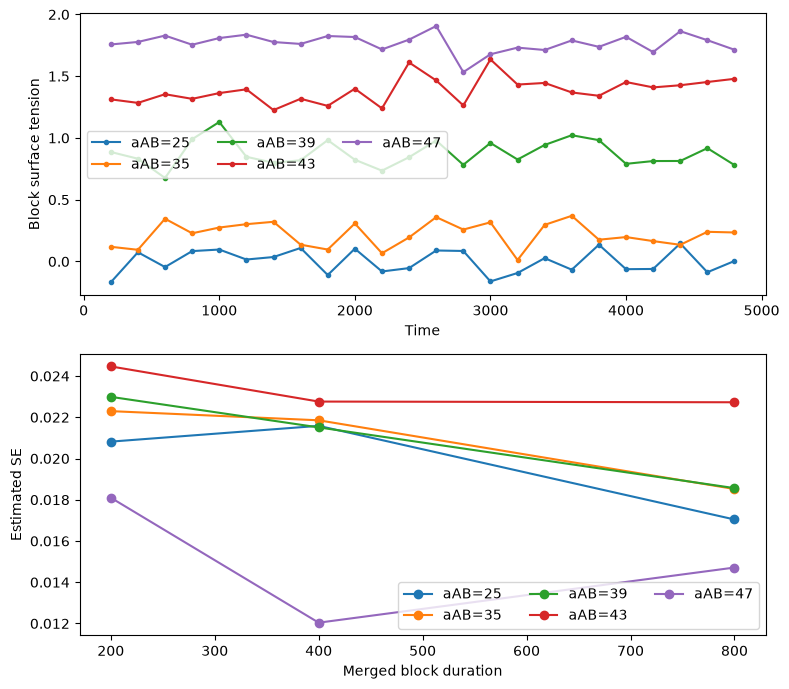

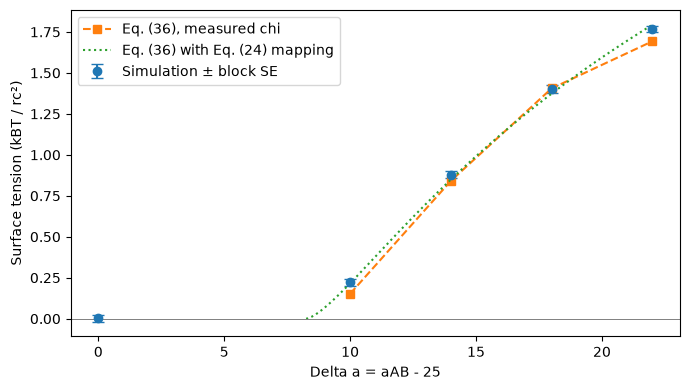

array([(25.,  0., 0.00367538, 0.02158346, 0.        , 0.        , 0.        , 0.        , 800., 20.),
       (35., 10., 0.22308073, 0.02229797, 2.74242224, 0.0248733 , 0.15230377, 0.21614423, 800., 20.),
       (39., 14., 0.87949603, 0.02299023, 3.98782222, 0.0402293 , 0.84077657, 0.84906823, 800., 20.),
       (43., 18., 1.39909307, 0.02446571, 5.2274035 , 0.09901445, 1.40520946, 1.37306117, 800., 20.),
       (47., 22., 1.76543799, 0.01809919, 5.99556996, 0.12427722, 1.69251096, 1.7931011 , 800., 20.)],
      dtype=[('aAB', '<f8'), ('delta_a', '<f8'), ('sigma', '<f8'), ('sigma_SE', '<f8'), ('chi', '<f8'), ('chi_SE', '<f8'), ('GW36_measured_chi', '<f8'), ('GW36_mapped_chi', '<f8'), ('discard_time', '<f8'), ('blocks', '<f8')])

Control compatible with zero within approx. 2 block SE: True
A stable demixed interface has positive tension; increasing Delta a generally increases tension.
Tension approaches zero at coexistence criticality, where phases become identical. The paper monomer fit uses chi_crit=2.36.
A failed control suggests bias or insufficient statistics. A passing control does not verify an overall factor: compare the magnitude to Eq. (36).
Inspect SE versus merged block duration. If it keeps increasing, extend the run/use larger blocks before interpreting error bars.


In [8]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = Path.cwd()
DATA = ROOT / 'data'

def csv(name):
    return np.atleast_1d(np.genfromtxt(DATA/name,delimiter=',',names=True,dtype=None,encoding='utf-8'))

def sem_reblock(values):
    """Report SE versus block size; retain the largest supported estimate."""
    v=np.asarray(values,float)
    if len(v)<4: raise ValueError('Need at least four production blocks; run longer.')
    out=[]
    for q in [1,2,4]:
        nb=len(v)//q
        if nb>=4:
            z=v[:nb*q].reshape(nb,q).mean(axis=1)
            out.append((q,nb,float(z.std(ddof=1)/np.sqrt(nb))))
    return max(z[2] for z in out),out

def profiles(tag,discard_time=None):
    m=json.loads((DATA/f'{tag}_manifest.json').read_text())
    raw=csv(f'{tag}_profile_blocks.csv');ids=np.unique(raw['block'])
    groups=[raw[raw['block']==i] for i in ids]
    assert len({len(g) for g in groups})==1
    assert np.all([np.allclose(g['x'],groups[0]['x']) for g in groups])
    assert len({int(g['frames'][0]) for g in groups})==1, 'Use equal full blocks.'
    x=groups[0]['x'];ra=np.array([g['rho_A'] for g in groups]);rb=np.array([g['rho_B'] for g in groups])
    la=np.array([g['rho_A_lab'] for g in groups]);lb=np.array([g['rho_B_lab'] for g in groups])
    start=np.array([g['t_start'][0] for g in groups]);end=np.array([g['t_end'][0] for g in groups])
    cut=m['equil']*m['dt'] if discard_time is None else discard_time
    keep=start>=cut-1e-9
    L=m['L'][0];windowA=(x>=.2*L)&(x<.3*L);windowB=(x>=.7*L)&(x<.8*L)
    phi=ra/(ra+rb)
    minorityAinB=ra[:,windowB].sum(axis=1)/(ra[:,windowB]+rb[:,windowB]).sum(axis=1)
    minorityBinA=rb[:,windowA].sum(axis=1)/(ra[:,windowA]+rb[:,windowA]).sum(axis=1)
    # Conservation: density integrals must recover NA=NB=N/2 per block.
    dx=m['L'][0]/len(x);area=m['L'][1]*m['L'][2]
    assert np.allclose(ra.sum(axis=1)*dx*area,m['num_part']/2)
    assert np.allclose(rb.sum(axis=1)*dx*area,m['num_part']/2)
    return dict(m=m,x=x,ra=ra,rb=rb,la=la,lb=lb,phi=phi,start=start,end=end,keep=keep,cut=cut,
                bphi=minorityAinB,aphi=minorityBinA,order=np.array([g['order'][0] for g in groups]),
                aligned=np.array([g['aligned_fraction'][0] for g in groups]),windowA=windowA,windowB=windowB)

def steady_candidate(d):
    """Exploratory tolerance diagnostic, not a proof of stationarity."""
    z=d['phi'];window=3
    if len(z)<2*window:return None
    target=z[-window:].mean(axis=0)
    dist=np.array([np.sqrt(np.mean((z[i-window+1:i+1].mean(axis=0)-target)**2))
                   for i in range(window-1,len(z))])
    for j in range(len(dist)-window+1):
        if np.all(dist[j:]<.03):return float(d['end'][j+window-1])
    return None

def diagnose(d):
    keep=d['keep']; n=int(keep.sum())
    if n<4:raise ValueError('Too few retained blocks after the chosen discard time.')
    if np.any(d['aligned'][keep]<.95) and d['m']['aab']>25:
        print('CAUTION: some frames lack a strong x slab; inspect morphology before extracting bulk chi.')
    vals=d['bphi'][keep];half=n//2
    e1,_=sem_reblock(vals[:half]) if half>=4 else (float('nan'),[])
    e2,_=sem_reblock(vals[half:]) if n-half>=4 else (float('nan'),[])
    drift=abs(vals[:half].mean()-vals[half:].mean())
    print(f'Cutoff t={d["cut"]:g}; {n} retained blocks; first/second-half bulk difference={drift:.4g}; combined SE={np.hypot(e1,e2):.4g}')
    print('Candidate steady time (rolling-profile RMS <0.03 relative to final 3 blocks):',steady_candidate(d))
    return drift,float(np.hypot(e1,e2))
# %% C4 reuses the four C3 runs; run the C3 cell first to save its table.
chi_table=csv('C3_chi_table.csv')
CONTROL_DISCARD_TIME=None
rows=[];reblocks=[]
fig,axes=plt.subplots(2,1,figsize=(8,7))
for a in [25,35,39,43,47]:
    tag='c4_control' if a==25 else f'c3_a{a}'
    m=json.loads((DATA/f'{tag}_manifest.json').read_text())
    block=csv(f'{tag}_pressure_blocks.csv')
    if a==25:
        cut=m['equil']*m['dt'] if CONTROL_DISCARD_TIME is None else CONTROL_DISCARD_TIME
        chi=0;chiSE=0
        control=profiles(tag,cut)
        phi_control=control['phi'][control['keep']].mean(axis=0)
        print('Control residual composition nonuniformity (RMS from 0.5):',float(np.sqrt(np.mean((phi_control-.5)**2))))
        if np.sqrt(np.mean((phi_control-.5)**2))>.05:print('WARNING: control labels have not fully mixed; inspect equilibration.')
    else:
        record=chi_table[np.isclose(chi_table['aAB'],a)][0]
        cut=float(record['discard_time']);chi=float(record['chi']);chiSE=float(record['chi_SE'])
    keep=block['t_start']>=cut-1e-9
    z=block['sigma_two_interfaces'][keep]
    assert np.all(block['frames'][keep]==block['frames'][keep][0])
    # Independent calculation verifies the saved factor of two.
    calc=.5*m['L'][0]*(block['Pxx']-.5*(block['Pyy']+block['Pzz']))
    assert np.allclose(calc,block['sigma_two_interfaces'],atol=1e-10)
    mean=float(z.mean());se,rb=sem_reblock(z)
    for q,nb,e in rb:reblocks.append([a,q,nb,q*m['block']*m['dt'],e])
    def gw36(c):return 0.75*3*1*1*c**.26*(1-2.36/c)**1.5 if c>2.36 else 0.
    theory=gw36(chi);mapped=gw36(.286*(a-25))
    rows.append([a,a-25,mean,se,chi,chiSE,theory,mapped,cut,len(z)])
    axes[0].plot(block['t_end'],block['sigma_two_interfaces'],'o-',ms=3,label=f'aAB={a}')
    axes[1].plot([v[0]*m['block']*m['dt'] for v in rb],[v[2] for v in rb],'o-',label=f'aAB={a}')
axes[0].set(xlabel='Time',ylabel='Block surface tension');axes[0].legend(ncol=3)
axes[1].set(xlabel='Merged block duration',ylabel='Estimated SE');axes[1].legend(ncol=3)
fig.tight_layout();fig.savefig(DATA/'C4_convergence.png',dpi=200);plt.show()
rows=np.array(rows)
np.savetxt(DATA/'C4_tension_table.csv',rows,delimiter=',',comments='',header='aAB,delta_a,sigma,sigma_SE,chi,chi_SE,GW36_measured_chi,GW36_mapped_chi,discard_time,blocks')
np.savetxt(DATA/'C4_reblocking.csv',reblocks,delimiter=',',comments='',header='aAB,merge_factor,blocks,block_time,sigma_SE')
fig,ax=plt.subplots(figsize=(7,4))
ax.errorbar(rows[:,1],rows[:,2],yerr=rows[:,3],fmt='o',capsize=4,label='Simulation ± block SE')
ax.plot(rows[1:,1],rows[1:,6],'s--',label='Eq. (36), measured chi')
xx=np.linspace(2.36/.286+.001,rows[:,1].max(),200);cc=.286*xx
ax.plot(xx,.75*3*cc**.26*(1-2.36/cc)**1.5,':',label='Eq. (36) with Eq. (24) mapping')
ax.axhline(0,color='grey',lw=.7);ax.set(xlabel='Delta a = aAB - 25',ylabel='Surface tension (kBT / rc²)')
ax.legend();fig.tight_layout();fig.savefig(DATA/'C4_surface_tension.png',dpi=200);plt.show()
display(csv('C4_tension_table.csv'))
print('Control compatible with zero within approx. 2 block SE:',bool(abs(rows[0,2])<=2*rows[0,3]))
print('A stable demixed interface has positive tension; increasing Delta a generally increases tension.')
print('Tension approaches zero at coexistence criticality, where phases become identical. The paper monomer fit uses chi_crit=2.36.')
print('A failed control suggests bias or insufficient statistics. A passing control does not verify an overall factor: compare the magnitude to Eq. (36).')
print('Inspect SE versus merged block duration. If it keeps increasing, extend the run/use larger blocks before interpreting error bars.')

## Part D: Validation for chains (N > 1)

*In the oral you should be able to:* explain why longer chains demix at
smaller Δa, and what Eq. (27)'s χN means for a symmetric blend.

For chains of equal length $N_A = N_B = N$, Eq. (18) gives the product
$\chi N$, with $\phi_A$ the fraction of A **beads** in the B-rich phase.
Demixing is governed by $\chi N$, so the values of $\Delta a$ that work
for monomers are far too large for chains: at $\Delta a = 16$ every chain
length used here demixes completely, no A bead is left in the B-rich
phase, $\phi_A = 0$ and Eq. (18) cannot be evaluated. That is why Part D uses
much smaller $\Delta a$, and different values for each $N$ (see the run
plan). Close to its critical point every interface is wide, and a chain
is several bead diameters long: check, for each run, that the part of the
profile you call bulk is really flat.

### D1) Snapshot

Provide a **snapshot** of equilibrated bead-spring chains with $N = 5$
($a = 25$ for every pair, cubic box), and a **number** characterising the
chains themselves: the mean-square end-to-end distance, compared with
that of an ideal chain with the same springs (derive it: $N - 1$
independent harmonic bonds with spring constant $C$). This is your check
that the springs and the initialisation are doing what you think; say
why the two numbers need not agree.

### D2) Two-phase simulations

Perform demixing simulations for chain lengths $N = 3$, $5$ and $10$, all
at $\Delta a = 3$ ($a_{AB} = 28$).

Deliver a **figure** with the composition profiles of the three chain
lengths on one set of axes, in the style of Fig. 6, so the effect of $N$
is visible in one figure, and a **snapshot** of each.

### D3) χ-parameter for chains

Measure χ for the chain systems, with a separate series of $\Delta a$
for each chain length:

| $N$ | $\Delta a$ |
|---|---|
| 3 | 3, 5, 7 |
| 5 | 2, 3.5, 5 |
| 10 | 1, 1.5, 2 |

($N = 3$ at $\Delta a = 3$ is the D2 run.)

Deliver a **table** of χ and $\chi N$ against $N$ and $\Delta a$, and a
**figure** comparing your $\chi N/\Delta a$ with Eq. (27) and Fig. 8.
Then answer the physical question: at fixed $\Delta a$, why do longer
chains demix more readily? Argue it from your table, from $\chi N$
rather than from the pictures.

*Results (D1-D3):* …

In [9]:
# D: chain statistics, composition profiles, chi(N) against Eq. (27)

## Lessons learned

What would you do differently if you started over? What surprised you?
What broke first in the conversion from MD to DPD, and how did you find
it? (Standing questions in the oral, so write the honest version.)

*Lessons learned:* …

## Hand-in

One zip per group, layout exactly:

```
<group>_A3.zip
├── A3.ipynb     this notebook, filled in and executed
│                (all outputs present; task cells untouched)
├── A3.html      python3 nb2html.py A3.ipynb
├── code/        all .c/.h + README.md; must build with
│                gcc -O3 *.c -o dpd -lm    (no binaries)
└── data/        every data file this notebook loads
```

Long runs are done in the terminal; record the exact commands in the
*Build & run log* and let the notebook load the saved output from
`data/`. Handed in executed, the notebook must open and display without
rerunning anything.

**Before you submit,** check your own zip:

```
python3 check_my_submission.py <group>_A3.zip --release A3.ipynb
```

where `--release` is a freshly downloaded, unmodified `A3.ipynb`. It
verifies the layout, that the task cells are untouched, that every cell
has been executed, that your C code compiles, and that every path and
link in the notebook is relative and present in the zip. Fix what it
reports, then submit. Setting up the Python environment
(`requirements.txt`, both helper scripts) is described on the Canvas page
*Working on the assignments*.